In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import json, warnings
from pathlib import Path
from datetime import datetime
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)

try:
    import lightgbm as lgb
    LIGHTGBM_AVAILABLE=True
except Exception:
    LIGHTGBM_AVAILABLE=False
    print("LightGBM unavailable. Run: !pip install lightgbm -q")

try:
    import xgboost as xgb
    XGBOOST_AVAILABLE=True
except Exception:
    XGBOOST_AVAILABLE=False
    print("XGBoost unavailable. Run: !pip install xgboost -q")

try:
    import shap
    SHAP_AVAILABLE=True
except Exception:
    SHAP_AVAILABLE=False
    print("SHAP unavailable. Run: !pip install shap -q")

if not (LIGHTGBM_AVAILABLE or XGBOOST_AVAILABLE):
    raise ImportError("Install LightGBM and/or XGBoost")

In [3]:
DRIVE_DIR=Path("/content/drive/MyDrive")
INPUT_FILE=DRIVE_DIR/"model_ready_category_dataset.csv"
OUT_DIR=DRIVE_DIR/"model_2_tree_based_rolling_origin_outputs"
OUT_DIR.mkdir(parents=True,exist_ok=True)

MODEL_1_RESULTS=DRIVE_DIR/"model_1_rolling_origin_outputs"/"model_1_outer_test_results.csv"

TARGET_COL="weekly_quantity"
DATE_COL="week_start"
CATEGORY_COL="Product Category"
RANDOM_STATE=42
SEASONAL_PERIOD=52

OUTER_ORIGINS={
    "spring_2025":"2025-04-07",
    "summer_2025":"2025-07-07",
    "early_autumn_2025":"2025-09-08",
    "q4_year_end_2025":"2025-10-06",
}
FORECAST_HORIZONS=[4,8,12]

INNER_CV_HORIZON=4
INNER_CV_OFFSETS_WEEKS=[12,8,4]

LAG_FEATURES=[1,2,4,8,12,26,52]
ROLLING_WINDOWS=[4,8,12,26]
OCCURRENCE_WINDOWS=[4,8,12]

TARGET_TRANSFORMATIONS=["raw","log1p"]
MAX_CONFIGS_PER_FAMILY=12

Shape: (6200, 3)
Categories: 40
Date range: 2023-01-09 to 2025-12-22


,scenario_id,outer_origin_label,outer_origin,horizon_weeks,test_start,test_end
0,spring_2025_h4,spring_2025,2025-04-07,4,2025-04-07,2025-04-28
1,spring_2025_h8,spring_2025,2025-04-07,8,2025-04-07,2025-05-26
2,spring_2025_h12,spring_2025,2025-04-07,12,2025-04-07,2025-06-23
3,summer_2025_h4,summer_2025,2025-07-07,4,2025-07-07,2025-07-28
4,summer_2025_h8,summer_2025,2025-07-07,8,2025-07-07,2025-08-25
5,summer_2025_h12,summer_2025,2025-07-07,12,2025-07-07,2025-09-22
6,early_autumn_2025_h4,early_autumn_2025,2025-09-08,4,2025-09-08,2025-09-29
7,early_autumn_2025_h8,early_autumn_2025,2025-09-08,8,2025-09-08,2025-10-27
8,early_autumn_2025_h12,early_autumn_2025,2025-09-08,12,2025-09-08,2025-11-24
9,q4_year_end_2025_h4,q4_year_end_2025,2025-10-06,4,2025-10-06,2025-10-27


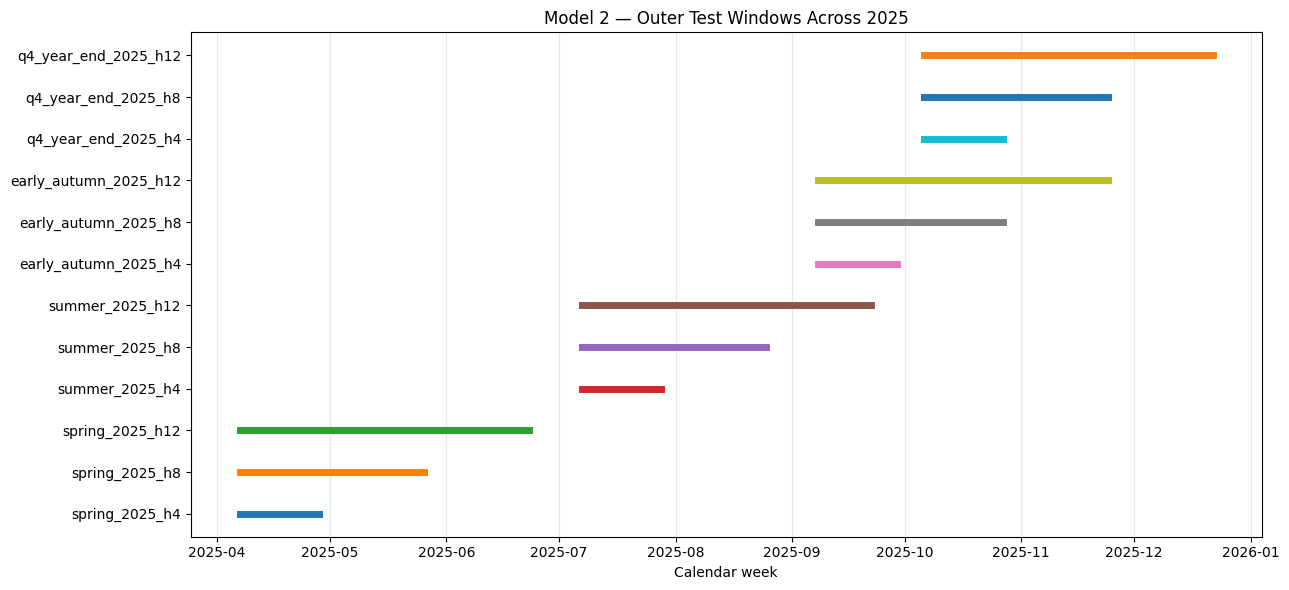

In [4]:
if not INPUT_FILE.exists():
    raise FileNotFoundError(INPUT_FILE)

raw=pd.read_csv(INPUT_FILE)
raw[DATE_COL]=pd.to_datetime(raw[DATE_COL])

required=[CATEGORY_COL,DATE_COL,TARGET_COL]
missing=[c for c in required if c not in raw.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

raw=raw[required].dropna(subset=required).copy()
raw=raw.sort_values([CATEGORY_COL,DATE_COL])

if raw.duplicated([CATEGORY_COL,DATE_COL]).any():
    raise ValueError("Duplicate category-week observations detected.")

categories=sorted(raw[CATEGORY_COL].unique())
dataset_min=raw[DATE_COL].min()
dataset_max=raw[DATE_COL].max()
full_weeks=pd.date_range(dataset_min,dataset_max,freq="7D")

parts=[]
for cat in categories:
    x=raw[raw[CATEGORY_COL]==cat].set_index(DATE_COL)[[TARGET_COL]].reindex(full_weeks)
    x.index.name=DATE_COL
    x[TARGET_COL]=x[TARGET_COL].fillna(0.0)
    x[CATEGORY_COL]=cat
    parts.append(x.reset_index())

panel=pd.concat(parts,ignore_index=True).sort_values([CATEGORY_COL,DATE_COL]).reset_index(drop=True)

print("Shape:",panel.shape)
print("Categories:",len(categories))
print("Date range:",dataset_min.date(),"to",dataset_max.date())

scenario_rows=[]
for label,origin_s in OUTER_ORIGINS.items():
    origin=pd.Timestamp(origin_s)
    if origin not in full_weeks:
        raise ValueError(f"{origin} is not aligned with the weekly calendar.")
    for h in FORECAST_HORIZONS:
        dates=pd.date_range(origin,periods=h,freq="7D")
        if dates[-1]>dataset_max:
            raise ValueError(f"{label}, h={h} exceeds dataset end.")
        scenario_rows.append({
            "scenario_id":f"{label}_h{h}",
            "outer_origin_label":label,
            "outer_origin":origin,
            "horizon_weeks":h,
            "test_start":dates[0],
            "test_end":dates[-1]
        })

scenarios=pd.DataFrame(scenario_rows)
scenarios.to_csv(OUT_DIR/"model_2_common_rolling_origin_scenarios.csv",index=False,encoding="utf-8-sig")
display(scenarios)

plt.figure(figsize=(13,6))
for i,r in scenarios.iterrows():
    plt.plot([r.test_start,r.test_end],[i,i],linewidth=5)
plt.yticks(range(len(scenarios)),scenarios.scenario_id)
plt.title("Model 2 — Outer Test Windows Across 2025")
plt.xlabel("Calendar week"); plt.grid(axis="x",alpha=.3); plt.tight_layout()
plt.savefig(OUT_DIR/"plot_outer_test_windows.png",dpi=160); plt.show()

In [5]:
EPS=1e-12

def mae(a,p):
    a,p=np.asarray(a,float),np.asarray(p,float)
    return float(np.mean(np.abs(a-p)))

def rmse(a,p):
    a,p=np.asarray(a,float),np.asarray(p,float)
    return float(np.sqrt(np.mean((a-p)**2)))

def mape(a,p):
    a,p=np.asarray(a,float),np.asarray(p,float)
    mask=np.abs(a)>EPS
    return np.nan if mask.sum()==0 else float(np.mean(np.abs((a[mask]-p[mask])/a[mask]))*100)

def smape(a,p):
    a,p=np.asarray(a,float),np.asarray(p,float)
    d=np.abs(a)+np.abs(p)
    return float(np.mean(np.where(d>EPS,2*np.abs(a-p)/d,0))*100)

def mase_scale_info(y_train,m=52):
    y=np.asarray(y_train,float)
    if len(y)<=m:
        return np.nan,"insufficient_history"
    scale=float(np.mean(np.abs(y[m:]-y[:-m])))
    if not np.isfinite(scale):
        return np.nan,"non_finite_scale"
    if scale<=EPS:
        return np.nan,"zero_seasonal_scale"
    return scale,"valid"

def evaluate(a,p,y_train,m=52):
    scale,status=mase_scale_info(y_train,m)
    return {
        "MAE":mae(a,p),
        "RMSE":rmse(a,p),
        "MAPE":mape(a,p),
        "MAPE_N":int(np.sum(np.abs(np.asarray(a,float))>EPS)),
        "sMAPE":smape(a,p),
        "MASE":np.nan if not np.isfinite(scale) else mae(a,p)/scale,
        "MASE_scale":scale,
        "MASE_status":status
    }

print("MASE: seasonal m=52; undefined zero seasonal scales remain NaN.")

MASE: seasonal m=52; undefined zero seasonal scales remain NaN.


In [6]:
def add_calendar_features(df):
    z=df.copy()
    iso=z[DATE_COL].dt.isocalendar()
    z["year"]=z[DATE_COL].dt.year.astype(int)
    z["month"]=z[DATE_COL].dt.month.astype(int)
    z["quarter"]=z[DATE_COL].dt.quarter.astype(int)
    z["week_of_year"]=iso.week.astype(int)
    z["week_sin"]=np.sin(2*np.pi*z["week_of_year"]/52.0)
    z["week_cos"]=np.cos(2*np.pi*z["week_of_year"]/52.0)
    z["month_sin"]=np.sin(2*np.pi*z["month"]/12.0)
    z["month_cos"]=np.cos(2*np.pi*z["month"]/12.0)
    return z

def category_mapping_from_training(train_df):
    cats=sorted(train_df[CATEGORY_COL].unique())
    return {c:i for i,c in enumerate(cats)}

def historical_features_for_series(values):
    y=np.asarray(values,float)
    f={}
    for lag in LAG_FEATURES:
        f[f"lag_{lag}"]=y[-lag] if len(y)>=lag else np.nan

    for w in ROLLING_WINDOWS:
        if len(y)>=1:
            recent=y[-min(w,len(y)):]
            f[f"rolling_mean_{w}"]=float(np.mean(recent))
            f[f"rolling_std_{w}"]=float(np.std(recent,ddof=1)) if len(recent)>=2 else 0.0
            f[f"rolling_min_{w}"]=float(np.min(recent))
            f[f"rolling_max_{w}"]=float(np.max(recent))
        else:
            for stat in ["mean","std","min","max"]:
                f[f"rolling_{stat}_{w}"]=np.nan

    pos=(y>0).astype(int)
    f["lag_1_demand_positive"]=pos[-1] if len(pos)>=1 else np.nan
    f["lag_2_demand_positive"]=pos[-2] if len(pos)>=2 else np.nan
    f["lag_1_zero"]=1-f["lag_1_demand_positive"] if np.isfinite(f["lag_1_demand_positive"]) else np.nan
    f["lag_2_zero"]=1-f["lag_2_demand_positive"] if np.isfinite(f["lag_2_demand_positive"]) else np.nan

    for w in OCCURRENCE_WINDOWS:
        recent=pos[-min(w,len(pos)):] if len(pos) else np.array([])
        f[f"recent_positive_ratio_{w}"]=float(np.mean(recent)) if len(recent) else np.nan
        f[f"recent_zero_ratio_{w}"]=1-f[f"recent_positive_ratio_{w}"] if len(recent) else np.nan

    streak=0
    for v in y[::-1]:
        if v==0: streak+=1
        else: break
    f["zero_streak"]=streak
    return f

def build_supervised_training(train_raw,category_map):
    rows=[]
    for cat in sorted(train_raw[CATEGORY_COL].unique()):
        d=train_raw[train_raw[CATEGORY_COL]==cat].sort_values(DATE_COL)
        dates=d[DATE_COL].tolist()
        vals=d[TARGET_COL].astype(float).values
        for i in range(len(d)):
            if i<max(LAG_FEATURES):
                continue
            row={DATE_COL:dates[i],CATEGORY_COL:cat,TARGET_COL:vals[i],
                 "category_encoded":category_map.get(cat,-1)}
            row.update(historical_features_for_series(vals[:i]))
            rows.append(row)

    z=pd.DataFrame(rows)
    z=add_calendar_features(z)
    return z

def build_future_feature_row(cat,date,history_values,category_map):
    row=pd.DataFrame([{DATE_COL:pd.Timestamp(date),CATEGORY_COL:cat,
                       "category_encoded":category_map.get(cat,-1)}])
    for k,v in historical_features_for_series(history_values).items():
        row[k]=v
    row=add_calendar_features(row)
    return row.iloc[0]

FEATURE_COLUMNS=[
    "category_encoded","year","month","quarter","week_of_year",
    "week_sin","week_cos","month_sin","month_cos"
]
FEATURE_COLUMNS += [f"lag_{x}" for x in LAG_FEATURES]
for w in ROLLING_WINDOWS:
    FEATURE_COLUMNS += [f"rolling_mean_{w}",f"rolling_std_{w}",f"rolling_min_{w}",f"rolling_max_{w}"]
FEATURE_COLUMNS += ["lag_1_demand_positive","lag_2_demand_positive","lag_1_zero","lag_2_zero"]
for w in OCCURRENCE_WINDOWS:
    FEATURE_COLUMNS += [f"recent_positive_ratio_{w}",f"recent_zero_ratio_{w}"]
FEATURE_COLUMNS += ["zero_streak"]

pd.DataFrame({"feature":FEATURE_COLUMNS}).to_csv(
    OUT_DIR/"model_2_feature_columns.csv",index=False,encoding="utf-8-sig")
print("Features:",len(FEATURE_COLUMNS))
display(pd.DataFrame({"feature":FEATURE_COLUMNS}))

Features: 43


,feature
0,category_encoded
1,year
2,month
3,quarter
4,week_of_year
5,week_sin
6,week_cos
7,month_sin
8,month_cos
9,lag_1


In [7]:
LIGHTGBM_GRID={
    "n_estimators":[300,500,800],
    "learning_rate":[0.02,0.03,0.05],
    "max_depth":[3,4,5,6],
    "num_leaves":[7,15,31],
    "min_child_samples":[15,25,40],
    "subsample":[0.8,0.9],
    "colsample_bytree":[0.8,0.9],
    "reg_alpha":[0.0,0.1],
    "reg_lambda":[1.0,3.0,5.0]
}
XGBOOST_GRID={
    "n_estimators":[300,500,800],
    "learning_rate":[0.02,0.03,0.05],
    "max_depth":[3,4,5,6],
    "min_child_weight":[3,5,10],
    "subsample":[0.8,0.9],
    "colsample_bytree":[0.8,0.9],
    "reg_alpha":[0.0,0.1],
    "reg_lambda":[1.0,3.0,5.0],
    "gamma":[0.0,1.0]
}

def full_grid(g):
    keys=list(g)
    return [dict(zip(keys,v)) for v in product(*[g[k] for k in keys])]

def sample_grid(g,n,seed):
    configs=full_grid(g)
    if len(configs)<=n: return configs
    rng=np.random.default_rng(seed)
    idx=rng.choice(len(configs),size=n,replace=False)
    return [configs[i] for i in idx]

CANDIDATES=[]
if LIGHTGBM_AVAILABLE:
    for i,p in enumerate(sample_grid(LIGHTGBM_GRID,MAX_CONFIGS_PER_FAMILY,RANDOM_STATE)):
        for tr in TARGET_TRANSFORMATIONS:
            CANDIDATES.append({"family":"LightGBM","config_id":f"lgbm_{i:02d}_{tr}",
                               "target_transformation":tr,**p,"random_state":RANDOM_STATE})
if XGBOOST_AVAILABLE:
    for i,p in enumerate(sample_grid(XGBOOST_GRID,MAX_CONFIGS_PER_FAMILY,RANDOM_STATE+1)):
        for tr in TARGET_TRANSFORMATIONS:
            CANDIDATES.append({"family":"XGBoost","config_id":f"xgb_{i:02d}_{tr}",
                               "target_transformation":tr,**p,
                               "objective":"reg:squarederror","random_state":RANDOM_STATE})

candidate_table=pd.DataFrame([
    {"trial_id":i+1,"model_family":c["family"],"config_id":c["config_id"],
     "target_transformation":c["target_transformation"],"config":json.dumps(c)}
    for i,c in enumerate(CANDIDATES)
])
candidate_table.to_csv(OUT_DIR/"model_2_candidate_configurations.csv",index=False,encoding="utf-8-sig")

print(f"TOTAL CANDIDATE CONFIGURATIONS: {len(CANDIDATES)}")
print("Each row below is one candidate model/hyperparameter trial.")
display(candidate_table)

TOTAL CANDIDATE CONFIGURATIONS: 48
Each row below is one candidate model/hyperparameter trial.


,trial_id,model_family,config_id,target_transformation,config
0,1,LightGBM,lgbm_00_raw,raw,"{""family"": ""LightGBM"", ""config_id"": ""lgbm_00_r..."
1,2,LightGBM,lgbm_00_log1p,log1p,"{""family"": ""LightGBM"", ""config_id"": ""lgbm_00_l..."
2,3,LightGBM,lgbm_01_raw,raw,"{""family"": ""LightGBM"", ""config_id"": ""lgbm_01_r..."
3,4,LightGBM,lgbm_01_log1p,log1p,"{""family"": ""LightGBM"", ""config_id"": ""lgbm_01_l..."
4,5,LightGBM,lgbm_02_raw,raw,"{""family"": ""LightGBM"", ""config_id"": ""lgbm_02_r..."
5,6,LightGBM,lgbm_02_log1p,log1p,"{""family"": ""LightGBM"", ""config_id"": ""lgbm_02_l..."
6,7,LightGBM,lgbm_03_raw,raw,"{""family"": ""LightGBM"", ""config_id"": ""lgbm_03_r..."
7,8,LightGBM,lgbm_03_log1p,log1p,"{""family"": ""LightGBM"", ""config_id"": ""lgbm_03_l..."
8,9,LightGBM,lgbm_04_raw,raw,"{""family"": ""LightGBM"", ""config_id"": ""lgbm_04_r..."
9,10,LightGBM,lgbm_04_log1p,log1p,"{""family"": ""LightGBM"", ""config_id"": ""lgbm_04_l..."


In [8]:
def transform_target(y,tr):
    y=np.asarray(y,float)
    return y if tr=="raw" else np.log1p(np.maximum(y,0))

def inverse_target(y,tr):
    y=np.asarray(y,float)
    return y if tr=="raw" else np.expm1(y)

def create_model(config):
    excluded={"family","config_id","target_transformation"}
    p={k:v for k,v in config.items() if k not in excluded}
    if config["family"]=="LightGBM":
        return lgb.LGBMRegressor(**p,verbose=-1,n_jobs=-1)
    if config["family"]=="XGBoost":
        return xgb.XGBRegressor(**p,n_jobs=-1,verbosity=0)
    raise ValueError(config["family"])

def fit_global_model(train_raw,config):
    cmap=category_mapping_from_training(train_raw)
    supervised=build_supervised_training(train_raw,cmap)
    X=supervised[FEATURE_COLUMNS].astype(float)
    y=transform_target(supervised[TARGET_COL].values,config["target_transformation"])
    model=create_model(config)
    model.fit(X,y)
    return model,cmap,supervised

def recursive_global_forecast(model,cmap,history_raw,forecast_dates,config):
    outputs=[]
    for cat in sorted(history_raw[CATEGORY_COL].unique()):
        hist=history_raw[history_raw[CATEGORY_COL]==cat].sort_values(DATE_COL)
        history_values=hist[TARGET_COL].astype(float).tolist()

        for date in pd.to_datetime(forecast_dates):
            row=build_future_feature_row(cat,date,history_values,cmap)
            X=pd.DataFrame([[row[c] for c in FEATURE_COLUMNS]],columns=FEATURE_COLUMNS).astype(float)
            pred_t=model.predict(X)[0]
            pred=float(max(0.0,inverse_target([pred_t],config["target_transformation"])[0]))
            outputs.append({CATEGORY_COL:cat,DATE_COL:date,"y_pred":pred})
            history_values.append(pred)
    return pd.DataFrame(outputs)

def inner_folds(outer_origin):
    ans=[]
    for fold,offset in enumerate(INNER_CV_OFFSETS_WEEKS,1):
        vo=outer_origin-pd.Timedelta(weeks=offset)
        dates=pd.date_range(vo,periods=INNER_CV_HORIZON,freq="7D")
        if dates[-1]>=outer_origin:
            raise AssertionError("Inner fold overlaps outer test.")
        ans.append((fold,vo,dates))
    return ans

def score_category_forecasts(pred_df,actual_df,history_raw):
    merged=actual_df[[CATEGORY_COL,DATE_COL,TARGET_COL]].merge(
        pred_df,on=[CATEGORY_COL,DATE_COL],how="left")
    if merged.y_pred.isna().any():
        raise ValueError("Missing predictions.")

    rows=[]
    for cat in categories:
        q=merged[merged[CATEGORY_COL]==cat].sort_values(DATE_COL)
        h=history_raw[history_raw[CATEGORY_COL]==cat].sort_values(DATE_COL)[TARGET_COL].values
        met=evaluate(q[TARGET_COL].values,q.y_pred.values,h,52)
        rows.append({CATEGORY_COL:cat,**met})
    return pd.DataFrame(rows),merged

In [9]:
all_trials=[]
selected_configs=[]

for origin_label,origin_s in OUTER_ORIGINS.items():
    origin=pd.Timestamp(origin_s)
    print("\n"+"="*100)
    print("TUNING FOR OUTER ORIGIN:",origin_label,origin.date())
    print("="*100)

    origin_trial_rows=[]

    for trial_id,config in enumerate(CANDIDATES,1):
        fold_rows=[]
        print(f"Trial {trial_id:02d}/{len(CANDIDATES)} | {config['family']} | {config['config_id']}")

        for fold,validation_origin,vdates in inner_folds(origin):
            train_raw=panel[panel[DATE_COL]<validation_origin].copy()
            actual=panel[panel[DATE_COL].isin(vdates)].copy()

            assert train_raw[DATE_COL].max()<actual[DATE_COL].min()
            assert actual[DATE_COL].max()<origin

            try:
                model,cmap,_=fit_global_model(train_raw,config)
                pred=recursive_global_forecast(model,cmap,train_raw,vdates,config)
                cat_scores,_=score_category_forecasts(pred,actual,train_raw)

                row={
                    "outer_origin_label":origin_label,"outer_origin":origin,
                    "trial_id":trial_id,"model_family":config["family"],
                    "config_id":config["config_id"],
                    "target_transformation":config["target_transformation"],
                    "config":json.dumps(config),"inner_fold":fold,
                    "validation_origin":validation_origin,"status":"ok",
                    "mean_MAE":cat_scores.MAE.mean(),
                    "mean_RMSE":cat_scores.RMSE.mean(),
                    "mean_MAPE":cat_scores.MAPE.mean(),
                    "mean_sMAPE":cat_scores.sMAPE.mean(),
                    "mean_MASE":cat_scores.MASE.mean(),
                    "median_MASE":cat_scores.MASE.median(),
                    "valid_MASE_N":int(cat_scores.MASE.notna().sum())
                }
            except Exception as e:
                row={
                    "outer_origin_label":origin_label,"outer_origin":origin,
                    "trial_id":trial_id,"model_family":config["family"],
                    "config_id":config["config_id"],
                    "target_transformation":config["target_transformation"],
                    "config":json.dumps(config),"inner_fold":fold,
                    "validation_origin":validation_origin,"status":"failed",
                    "mean_MAE":np.nan,"mean_RMSE":np.nan,"mean_MAPE":np.nan,
                    "mean_sMAPE":np.nan,"mean_MASE":np.nan,"median_MASE":np.nan,
                    "valid_MASE_N":0,"error":str(e)
                }
            fold_rows.append(row)
            all_trials.append(row)

        pd.DataFrame(all_trials).to_csv(
            OUT_DIR/"model_2_inner_cv_all_trials.csv",index=False,encoding="utf-8-sig")

    t=pd.DataFrame([x for x in all_trials if x["outer_origin_label"]==origin_label])
    ok=t[t.status=="ok"].copy()
    summary=(ok.groupby(
        ["trial_id","model_family","config_id","target_transformation","config"],as_index=False)
        .agg(cv_mean_MASE=("mean_MASE","mean"),
             cv_std_MASE=("mean_MASE","std"),
             cv_mean_sMAPE=("mean_sMAPE","mean"),
             cv_mean_RMSE=("mean_RMSE","mean"),
             cv_mean_MAE=("mean_MAE","mean"),
             successful_folds=("inner_fold","nunique")))

    eligible=summary[summary.successful_folds==len(INNER_CV_OFFSETS_WEEKS)].copy()
    if eligible.empty:
        raise RuntimeError(f"No configuration completed all folds for {origin_label}")

    if eligible.cv_mean_MASE.notna().any():
        ranked=eligible.sort_values(
            ["cv_mean_MASE","cv_std_MASE","cv_mean_RMSE","cv_mean_MAE"],na_position="last")
        selection_metric="mean_category_MASE"
        selection_score=float(ranked.iloc[0].cv_mean_MASE)
    else:
        ranked=eligible.sort_values(["cv_mean_sMAPE","cv_mean_RMSE","cv_mean_MAE"])
        selection_metric="mean_category_sMAPE_fallback"
        selection_score=float(ranked.iloc[0].cv_mean_sMAPE)

    best=ranked.iloc[0]
    selected_configs.append({
        "outer_origin_label":origin_label,"outer_origin":origin,
        "trial_id":int(best.trial_id),"model_family":best.model_family,
        "config_id":best.config_id,"target_transformation":best.target_transformation,
        "config":best.config,"selection_metric":selection_metric,
        "selection_score":selection_score,"cv_mean_MASE":best.cv_mean_MASE,
        "cv_std_MASE":best.cv_std_MASE,"cv_mean_sMAPE":best.cv_mean_sMAPE,
        "cv_mean_RMSE":best.cv_mean_RMSE,"cv_mean_MAE":best.cv_mean_MAE
    })

    print("SELECTED:",best.config_id,"|",selection_metric,"=",selection_score)

trials_df=pd.DataFrame(all_trials)
selected_df=pd.DataFrame(selected_configs)
selected_df.to_csv(OUT_DIR/"model_2_selected_configurations.csv",index=False,encoding="utf-8-sig")
display(selected_df)


TUNING FOR OUTER ORIGIN: spring_2025 2025-04-07
Trial 01/48 | LightGBM | lgbm_00_raw
Trial 02/48 | LightGBM | lgbm_00_log1p
Trial 03/48 | LightGBM | lgbm_01_raw
Trial 04/48 | LightGBM | lgbm_01_log1p
Trial 05/48 | LightGBM | lgbm_02_raw
Trial 06/48 | LightGBM | lgbm_02_log1p
Trial 07/48 | LightGBM | lgbm_03_raw
Trial 08/48 | LightGBM | lgbm_03_log1p
Trial 09/48 | LightGBM | lgbm_04_raw
Trial 10/48 | LightGBM | lgbm_04_log1p
Trial 11/48 | LightGBM | lgbm_05_raw
Trial 12/48 | LightGBM | lgbm_05_log1p
Trial 13/48 | LightGBM | lgbm_06_raw
Trial 14/48 | LightGBM | lgbm_06_log1p
Trial 15/48 | LightGBM | lgbm_07_raw
Trial 16/48 | LightGBM | lgbm_07_log1p
Trial 17/48 | LightGBM | lgbm_08_raw
Trial 18/48 | LightGBM | lgbm_08_log1p
Trial 19/48 | LightGBM | lgbm_09_raw
Trial 20/48 | LightGBM | lgbm_09_log1p
Trial 21/48 | LightGBM | lgbm_10_raw
Trial 22/48 | LightGBM | lgbm_10_log1p
Trial 23/48 | LightGBM | lgbm_11_raw
Trial 24/48 | LightGBM | lgbm_11_log1p
Trial 25/48 | XGBoost | xgb_00_raw
Tria

,outer_origin_label,outer_origin,trial_id,model_family,config_id,target_transformation,config,selection_metric,selection_score,cv_mean_MASE,cv_std_MASE,cv_mean_sMAPE,cv_mean_RMSE,cv_mean_MAE
0,spring_2025,2025-04-07,34,XGBoost,xgb_04_log1p,log1p,"{""family"": ""XGBoost"", ""config_id"": ""xgb_04_log...",mean_category_MASE,1.337849,1.337849,1.102171,151.391938,80.827491,65.268587
1,summer_2025,2025-07-07,20,LightGBM,lgbm_09_log1p,log1p,"{""family"": ""LightGBM"", ""config_id"": ""lgbm_09_l...",mean_category_MASE,0.685664,0.685664,0.393320,136.312670,56.544315,46.252753
2,early_autumn_2025,2025-09-08,40,XGBoost,xgb_07_log1p,log1p,"{""family"": ""XGBoost"", ""config_id"": ""xgb_07_log...",mean_category_MASE,0.358449,0.358449,0.185068,138.806178,38.122819,29.073375
3,q4_year_end_2025,2025-10-06,26,XGBoost,xgb_00_log1p,log1p,"{""family"": ""XGBoost"", ""config_id"": ""xgb_00_log...",mean_category_MASE,0.872235,0.872235,0.860905,139.238826,76.937762,61.469054


,trial_id,model_family,config_id,target_transformation,mean_inner_MASE,std_inner_MASE,mean_inner_sMAPE,completed_folds
33,34,XGBoost,xgb_04_log1p,log1p,0.865663,0.787886,142.666440,12
19,20,LightGBM,lgbm_09_log1p,log1p,0.868088,0.814399,142.425675,12
29,30,XGBoost,xgb_02_log1p,log1p,0.880148,0.804727,138.066781,12
23,24,LightGBM,lgbm_11_log1p,log1p,0.909066,0.784230,143.697461,12
39,40,XGBoost,xgb_07_log1p,log1p,0.909406,0.809543,141.562014,12
21,22,LightGBM,lgbm_10_log1p,log1p,0.911487,0.819638,141.416374,12
7,8,LightGBM,lgbm_03_log1p,log1p,0.920417,0.832776,139.463722,12
45,46,XGBoost,xgb_10_log1p,log1p,0.932062,0.851662,143.293243,12
13,14,LightGBM,lgbm_06_log1p,log1p,0.935366,0.838638,145.814364,12
27,28,XGBoost,xgb_01_log1p,log1p,0.939728,0.853852,147.345847,12


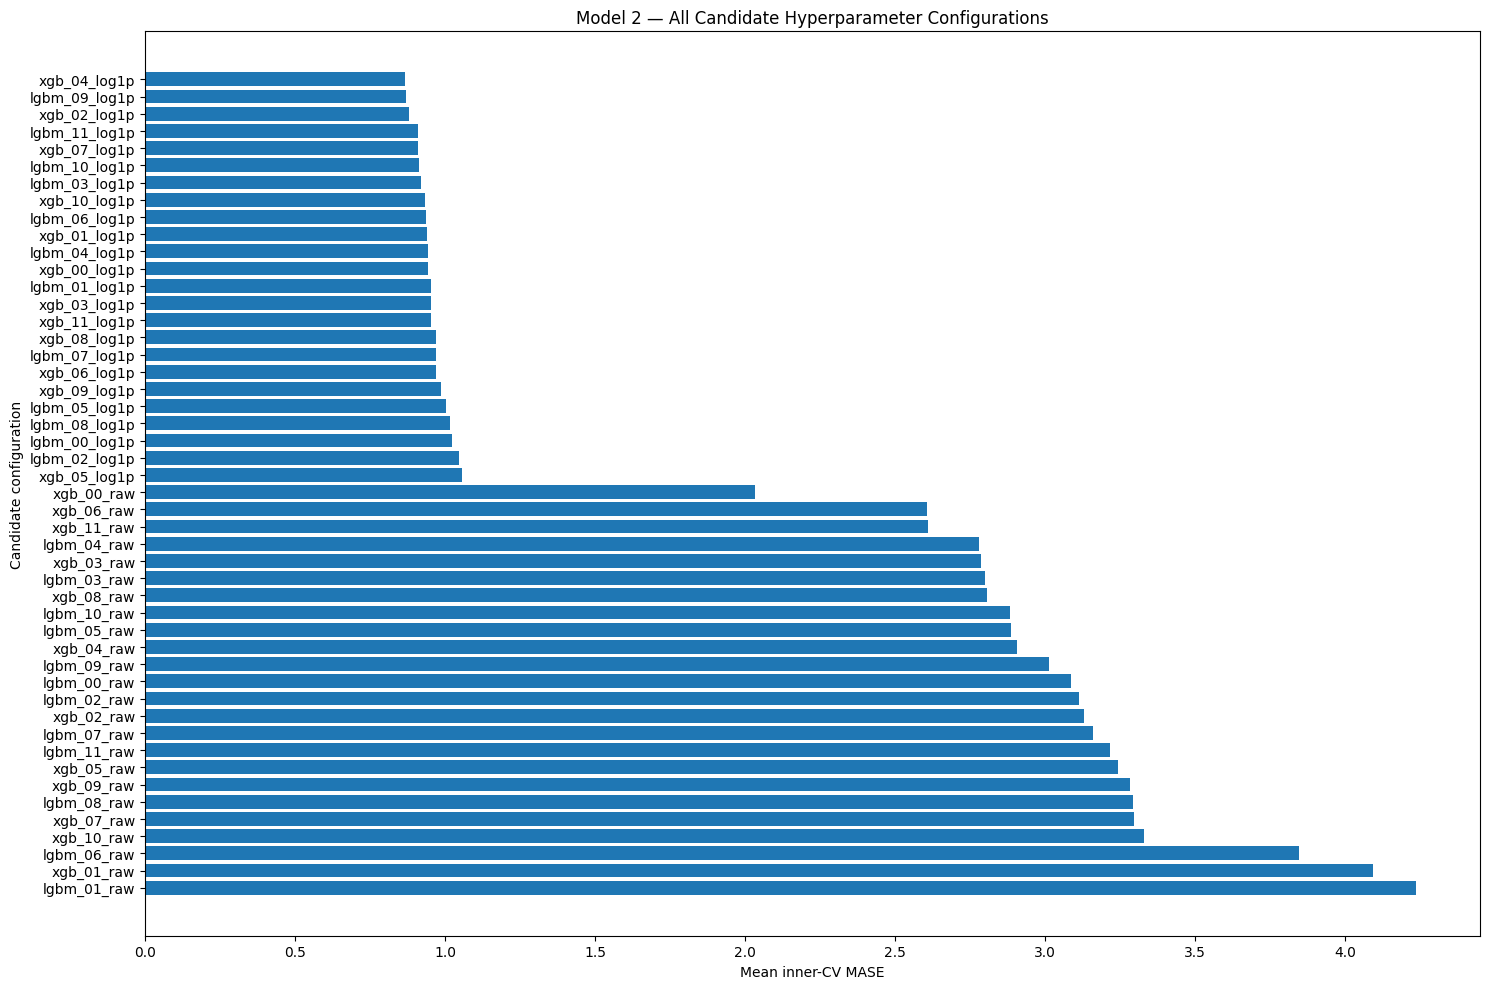

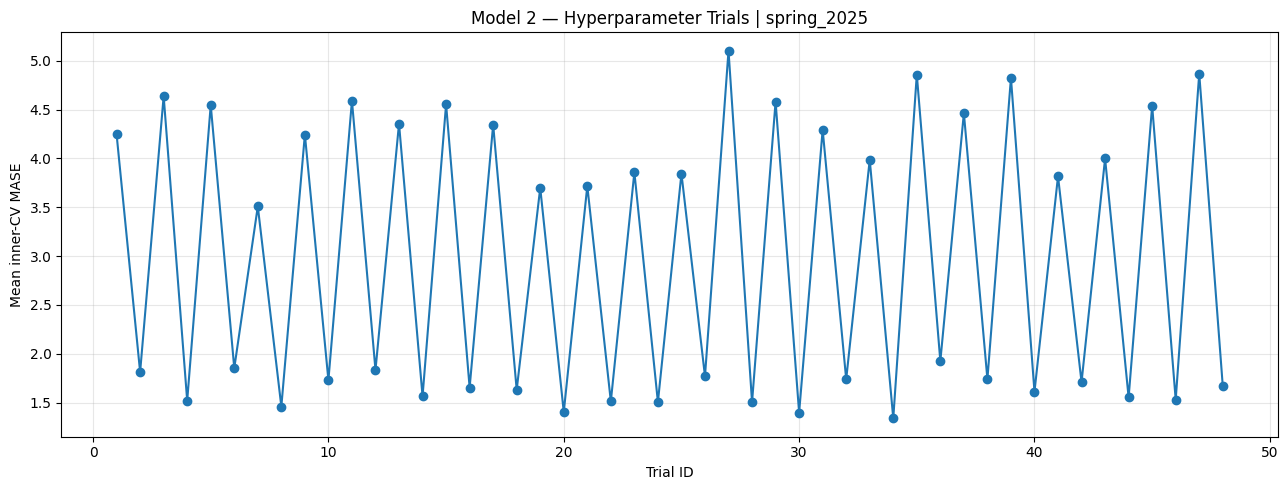

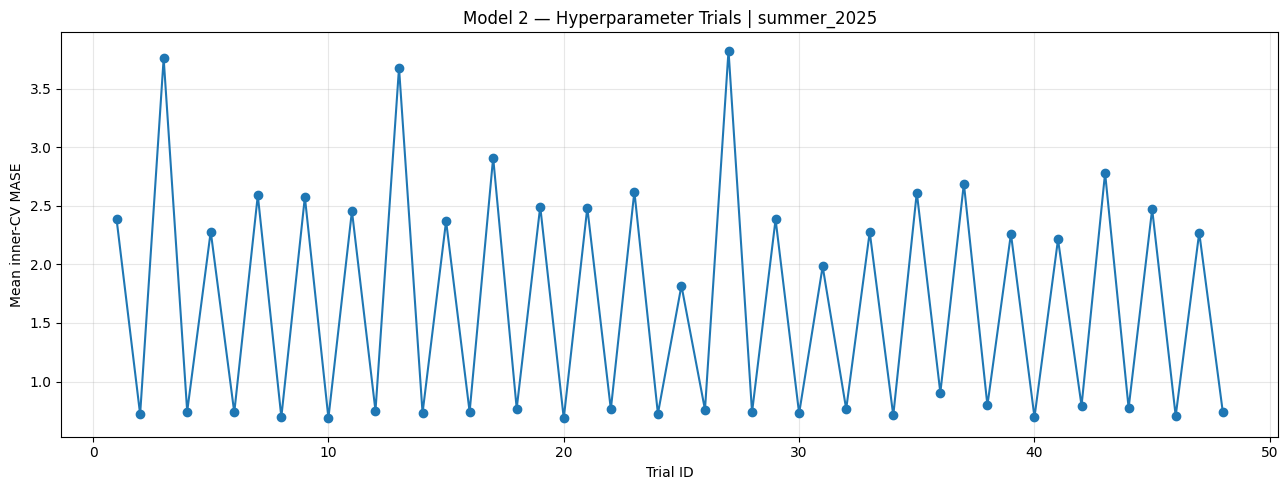

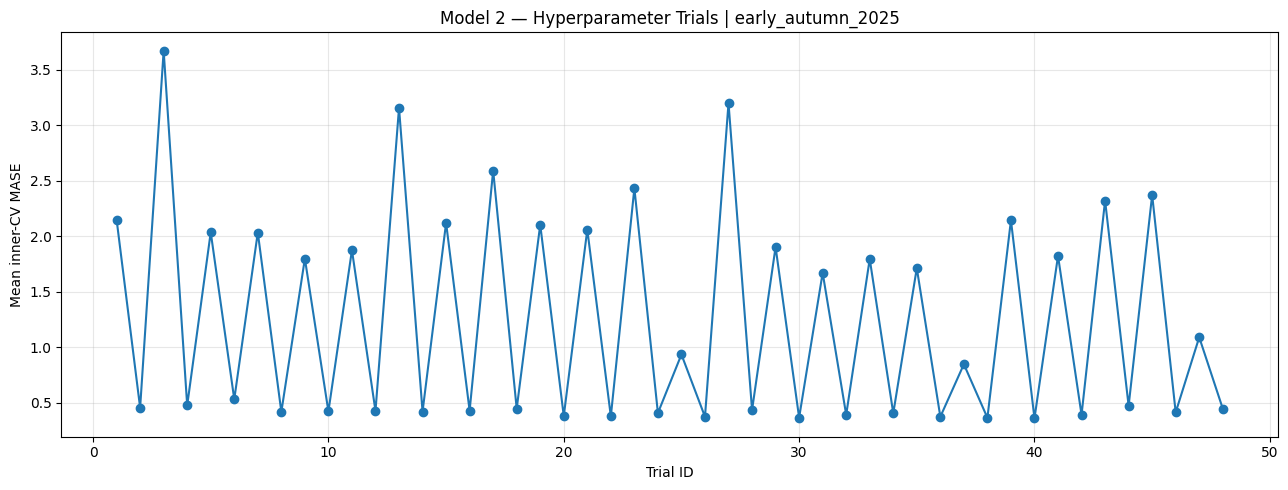

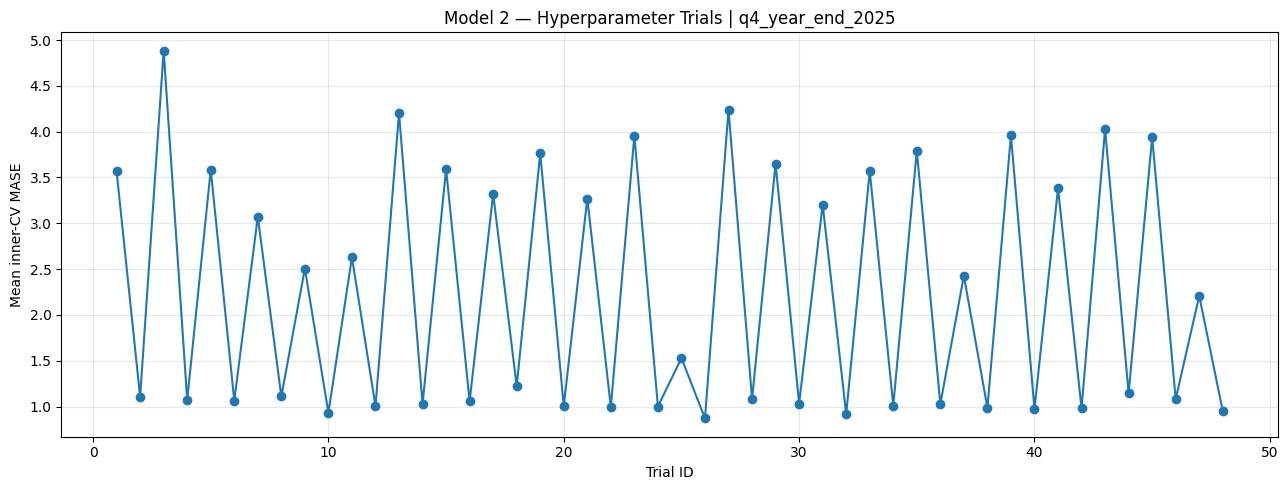

In [10]:
trial_summary=(trials_df[trials_df.status=="ok"]
    .groupby(["trial_id","model_family","config_id","target_transformation"],as_index=False)
    .agg(mean_inner_MASE=("mean_MASE","mean"),
         std_inner_MASE=("mean_MASE","std"),
         mean_inner_sMAPE=("mean_sMAPE","mean"),
         completed_folds=("inner_fold","count"))
    .sort_values("mean_inner_MASE"))

trial_summary.to_csv(OUT_DIR/"model_2_all_candidate_performance.csv",index=False,encoding="utf-8-sig")
display(trial_summary)

plt.figure(figsize=(15,10))
plt.barh(trial_summary.config_id.astype(str),trial_summary.mean_inner_MASE)
plt.xlabel("Mean inner-CV MASE")
plt.ylabel("Candidate configuration")
plt.title("Model 2 — All Candidate Hyperparameter Configurations")
plt.gca().invert_yaxis(); plt.tight_layout()
plt.savefig(OUT_DIR/"plot_all_candidate_cv_mase.png",dpi=160); plt.show()

for label in OUTER_ORIGINS:
    q=trials_df[(trials_df.outer_origin_label==label)&(trials_df.status=="ok")]
    q=(q.groupby(["trial_id","config_id"],as_index=False)
       .agg(mean_MASE=("mean_MASE","mean")).sort_values("trial_id"))
    plt.figure(figsize=(13,5))
    plt.plot(q.trial_id,q.mean_MASE,marker="o")
    plt.xlabel("Trial ID"); plt.ylabel("Mean inner-CV MASE")
    plt.title(f"Model 2 — Hyperparameter Trials | {label}")
    plt.grid(alpha=.3); plt.tight_layout()
    plt.savefig(OUT_DIR/f"plot_trials_{label}.png",dpi=160); plt.show()

In [11]:
outer_results=[]
outer_forecasts=[]
trained_models={}

for _,sel in selected_df.iterrows():
    label=sel.outer_origin_label
    origin=pd.Timestamp(sel.outer_origin)
    config=json.loads(sel.config)

    print("\n"+"="*100)
    print("OUTER TEST:",label,"| selected:",config["config_id"])
    print("="*100)

    train_raw=panel[panel[DATE_COL]<origin].copy()
    assert train_raw[DATE_COL].max()<origin

    model,cmap,supervised=fit_global_model(train_raw,config)
    trained_models[label]={"model":model,"config":config,"cmap":cmap,
                           "supervised":supervised,"train_raw":train_raw}

    max_dates=pd.date_range(origin,periods=max(FORECAST_HORIZONS),freq="7D")
    pred12=recursive_global_forecast(model,cmap,train_raw,max_dates,config)

    for h in FORECAST_HORIZONS:
        dates=max_dates[:h]
        actual=panel[panel[DATE_COL].isin(dates)].copy()
        pred=pred12[pred12[DATE_COL].isin(dates)].copy()
        cat_scores,merged=score_category_forecasts(pred,actual,train_raw)

        sid=f"{label}_h{h}"
        for _,r in cat_scores.iterrows():
            outer_results.append({
                "scenario_id":sid,"outer_origin_label":label,"outer_origin":origin,
                "horizon_weeks":h,"test_start":dates[0],"test_end":dates[-1],
                CATEGORY_COL:r[CATEGORY_COL],
                "selected_model_family":config["family"],
                "selected_config_id":config["config_id"],
                "target_transformation":config["target_transformation"],
                "selection_metric":sel.selection_metric,
                "cv_mean_MASE":sel.cv_mean_MASE,
                "cv_mean_sMAPE":sel.cv_mean_sMAPE,
                "MAE":r.MAE,"RMSE":r.RMSE,"MAPE":r.MAPE,"MAPE_N":r.MAPE_N,
                "sMAPE":r.sMAPE,"MASE":r.MASE,
                "MASE_scale":r.MASE_scale,"MASE_status":r.MASE_status
            })

        merged=merged.rename(columns={TARGET_COL:"y_true"})
        merged["scenario_id"]=sid
        merged["outer_origin_label"]=label
        merged["outer_origin"]=origin
        merged["horizon_weeks"]=h
        merged["selected_model_family"]=config["family"]
        merged["selected_config_id"]=config["config_id"]
        merged["target_transformation"]=config["target_transformation"]
        merged["absolute_error"]=np.abs(merged.y_true-merged.y_pred)
        outer_forecasts.append(merged)

    pd.DataFrame(outer_results).to_csv(
        OUT_DIR/"model_2_outer_test_results.csv",index=False,encoding="utf-8-sig")
    pd.concat(outer_forecasts,ignore_index=True).to_csv(
        OUT_DIR/"model_2_outer_forecasts.csv",index=False,encoding="utf-8-sig")

test_df=pd.DataFrame(outer_results)
forecasts_df=pd.concat(outer_forecasts,ignore_index=True)

print("\nOUTER BACKTEST COMPLETE")
print("Category-level outer evaluations:",len(test_df))
print("Expected:",len(categories)*len(OUTER_ORIGINS)*len(FORECAST_HORIZONS))
print("Valid MASE:",test_df.MASE.notna().sum(),"| Undefined MASE:",test_df.MASE.isna().sum())


OUTER TEST: spring_2025 | selected: xgb_04_log1p

OUTER TEST: summer_2025 | selected: lgbm_09_log1p

OUTER TEST: early_autumn_2025 | selected: xgb_07_log1p

OUTER TEST: q4_year_end_2025 | selected: xgb_00_log1p

OUTER BACKTEST COMPLETE
Category-level outer evaluations: 480
Expected: 480
Valid MASE: 468 | Undefined MASE: 12


In [12]:
valid_scale=test_df.MASE_status.eq("valid")
expected=len(categories)*len(OUTER_ORIGINS)*len(FORECAST_HORIZONS)

excluded_features=[
    TARGET_COL,"weekly_revenue","transaction_count","active_customer_count",
    "unique_customers","unique_skus","demand_positive"
]

audit=pd.DataFrame([
    {"check":"Inner validation origins precede outer origins",
     "passed":bool((trials_df.validation_origin<trials_df.outer_origin).all())},
    {"check":"Every outer test starts at its declared forecast origin",
     "passed":bool((test_df.test_start==test_df.outer_origin).all())},
    {"check":"Expected 40 × 4 × 3 category-level outer evaluations",
     "passed":bool(len(test_df)==expected)},
    {"check":"No same-week target/business outcome variables in feature list",
     "passed":bool(not any(x in FEATURE_COLUMNS for x in excluded_features))},
    {"check":"All target-derived feature names are explicitly historical",
     "passed":bool(all(
         (x.startswith("lag_") or x.startswith("rolling_") or
          x.startswith("recent_") or x=="zero_streak" or
          x in ["category_encoded","year","month","quarter","week_of_year",
                "week_sin","week_cos","month_sin","month_cos"])
         for x in FEATURE_COLUMNS))},
    {"check":"Every valid MASE has finite positive m=52 scale",
     "passed":bool(np.isfinite(test_df.loc[valid_scale,"MASE_scale"]).all()
                   and (test_df.loc[valid_scale,"MASE_scale"]>0).all())},
    {"check":"Undefined MASE is explicitly NaN rather than rescaled",
     "passed":bool(test_df.loc[~valid_scale,"MASE"].isna().all())}
])

audit.to_csv(OUT_DIR/"model_2_integrity_audit.csv",index=False,encoding="utf-8-sig")
display(audit)
if not audit.passed.all():
    raise AssertionError("Model 2 integrity audit failed.")

,check,passed
0,Inner validation origins precede outer origins,True
1,Every outer test starts at its declared foreca...,True
2,Expected 40 × 4 × 3 category-level outer evalu...,True
3,No same-week target/business outcome variables...,True
4,All target-derived feature names are explicitl...,True
5,Every valid MASE has finite positive m=52 scale,True
6,Undefined MASE is explicitly NaN rather than r...,True


In [14]:
scenario_summary=(test_df.groupby(
    ["scenario_id","outer_origin_label","outer_origin","horizon_weeks"],as_index=False)
    .agg(mean_MAE=("MAE","mean"),
         mean_RMSE=("RMSE","mean"),
         mean_MAPE=("MAPE","mean"),
         mean_sMAPE=("sMAPE","mean"),
         mean_MASE=("MASE","mean"),
         median_MASE=("MASE","median"),
         std_MASE=("MASE","std"),
         valid_MASE_N=("MASE","count"),
         total_categories=(CATEGORY_COL,"nunique")))

overall=pd.DataFrame([{
    "Model":"Model 2 - Global Tree-Based Forecasting",
    "mean_MAE":test_df.MAE.mean(),
    "mean_RMSE":test_df.RMSE.mean(),
    "mean_MAPE":test_df.MAPE.mean(),
    "mean_sMAPE":test_df.sMAPE.mean(),
    "mean_MASE":test_df.MASE.mean(),
    "median_MASE":test_df.MASE.median(),
    "valid_MASE_evaluations":int(test_df.MASE.notna().sum()),
    "undefined_MASE_evaluations":int(test_df.MASE.isna().sum()),
    "n_outer_evaluations":len(test_df)
}])

scenario_summary.to_csv(OUT_DIR/"model_2_scenario_summary.csv",index=False,encoding="utf-8-sig")
overall.to_csv(OUT_DIR/"model_2_overall_summary.csv",index=False,encoding="utf-8-sig")
display(scenario_summary)
display(overall)

,scenario_id,outer_origin_label,outer_origin,horizon_weeks,mean_MAE,mean_RMSE,mean_MAPE,mean_sMAPE,mean_MASE,median_MASE,std_MASE,valid_MASE_N,total_categories
0,early_autumn_2025_h12,early_autumn_2025,2025-09-08,12,61.311740,96.200512,104.572489,137.413579,1.849016,0.672654,2.817721,39,40
1,early_autumn_2025_h4,early_autumn_2025,2025-09-08,4,102.871861,131.011301,60.618619,131.938362,2.217935,1.215859,2.917729,39,40
2,early_autumn_2025_h8,early_autumn_2025,2025-09-08,8,84.323507,116.425042,87.670694,129.940215,2.360191,0.886847,3.418034,39,40
3,q4_year_end_2025_h12,q4_year_end_2025,2025-10-06,12,31.230481,49.135379,111.080619,135.368626,0.625442,0.285788,0.837999,39,40
4,q4_year_end_2025_h4,q4_year_end_2025,2025-10-06,4,68.930843,79.622461,98.490126,97.177987,0.921228,0.354428,1.290378,39,40
5,q4_year_end_2025_h8,q4_year_end_2025,2025-10-06,8,41.936503,58.678296,124.772918,121.897855,0.685443,0.331599,0.829846,39,40
6,spring_2025_h12,spring_2025,2025-04-07,12,66.339334,87.652774,142.721049,140.771326,1.763995,0.870575,3.441628,39,40
7,spring_2025_h4,spring_2025,2025-04-07,4,102.340448,115.606123,111.917908,133.182280,1.449998,1.174403,1.475485,39,40
8,spring_2025_h8,spring_2025,2025-04-07,8,78.553871,101.788619,84.357556,133.306431,1.650096,0.879230,2.597876,39,40
9,summer_2025_h12,summer_2025,2025-07-07,12,82.717827,135.767265,90.977500,149.016501,1.170247,0.650147,1.370613,39,40


,Model,mean_MAE,mean_RMSE,mean_MAPE,mean_sMAPE,mean_MASE,median_MASE,valid_MASE_evaluations,undefined_MASE_evaluations,n_outer_evaluations
0,Model 2 - Global Tree-Based Forecasting,63.757185,86.548685,101.94945,130.535167,1.266963,0.53186,468,12,480


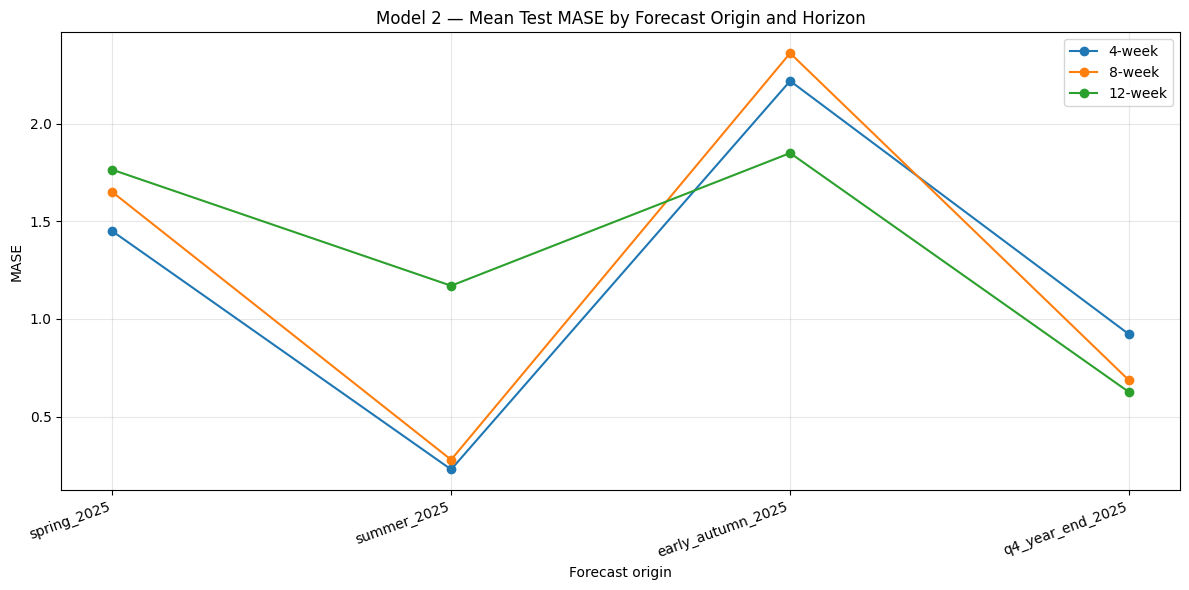

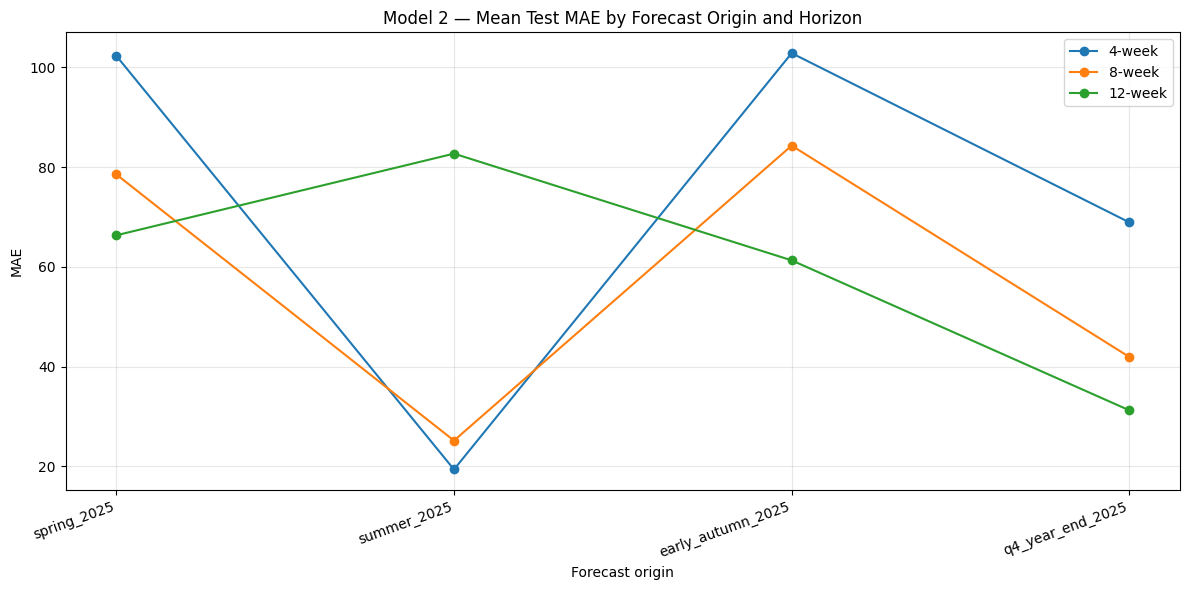

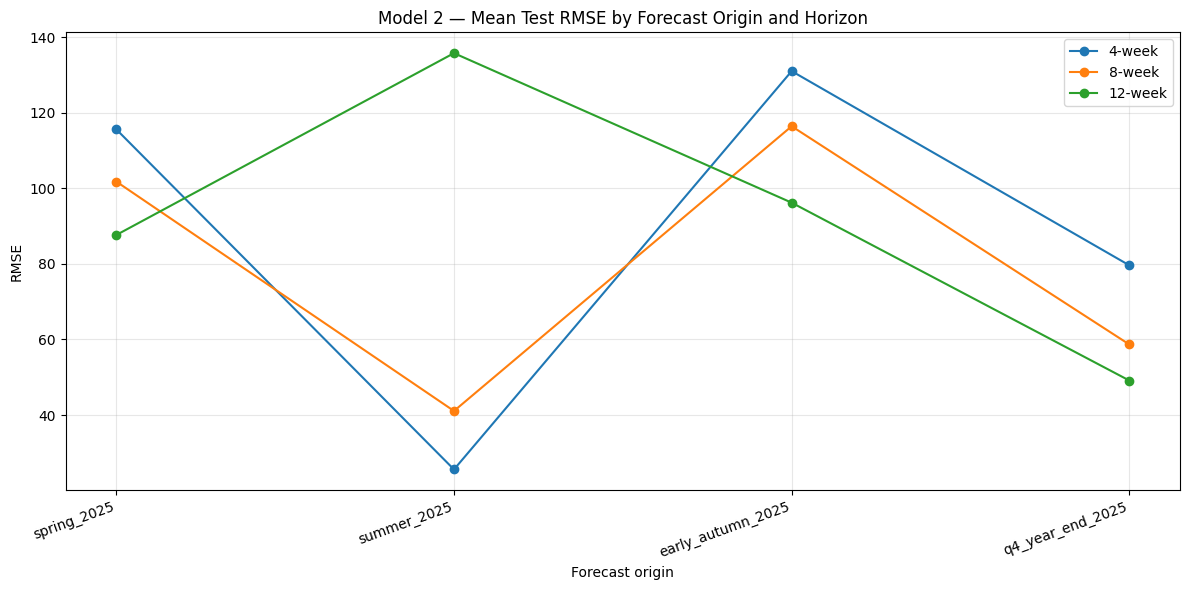

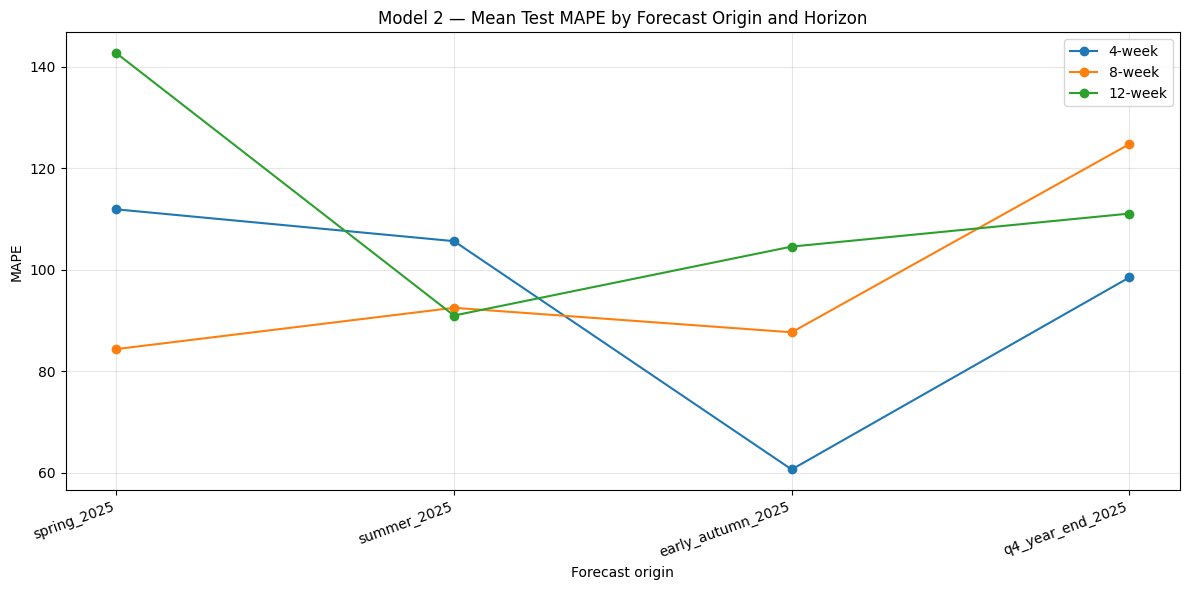

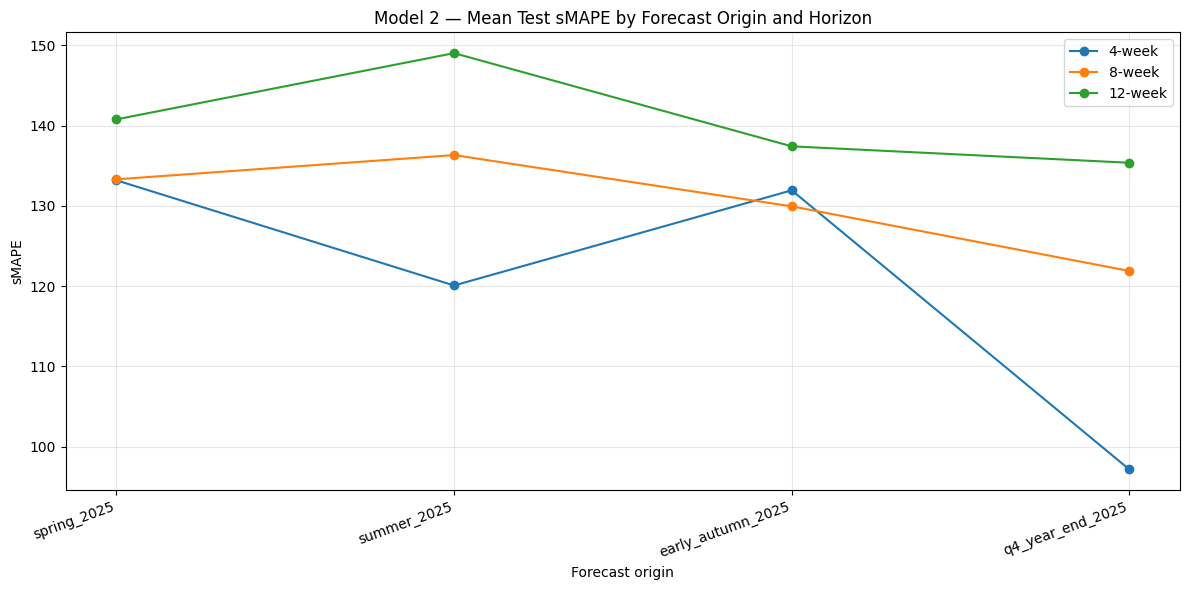

In [15]:
origin_order=list(OUTER_ORIGINS)

def metric_plot(metric):
    z=test_df.groupby(["outer_origin_label","horizon_weeks"],as_index=False)[metric].mean()
    z["outer_origin_label"]=pd.Categorical(z.outer_origin_label,origin_order,ordered=True)
    z=z.sort_values(["outer_origin_label","horizon_weeks"])
    plt.figure(figsize=(12,6))
    for h in FORECAST_HORIZONS:
        q=z[z.horizon_weeks==h]
        plt.plot(q.outer_origin_label.astype(str),q[metric],marker="o",label=f"{h}-week")
    plt.title(f"Model 2 — Mean Test {metric} by Forecast Origin and Horizon")
    plt.xlabel("Forecast origin"); plt.ylabel(metric); plt.legend()
    plt.grid(alpha=.3); plt.xticks(rotation=20,ha="right"); plt.tight_layout()
    plt.savefig(OUT_DIR/f"plot_{metric.lower()}_by_origin_horizon.png",dpi=160); plt.show()

for metric in ["MASE","MAE","RMSE","MAPE","sMAPE"]:
    metric_plot(metric)

,scenario_id,Model_1_MAE,Model_1_RMSE,Model_1_MAPE,Model_1_sMAPE,Model_1_MASE,Model_2_MAE,Model_2_RMSE,Model_2_MAPE,Model_2_sMAPE,Model_2_MASE
0,early_autumn_2025_h12,82.413420,106.175525,243.711668,79.963443,1.413853,61.311740,96.200512,104.572489,137.413579,1.849016
1,early_autumn_2025_h4,114.273325,134.266581,72.322718,80.589350,2.216187,102.871861,131.011301,60.618619,131.938362,2.217935
2,early_autumn_2025_h8,98.906593,120.618065,92.803371,73.662594,1.712905,84.323507,116.425042,87.670694,129.940215,2.360191
3,q4_year_end_2025_h12,63.640188,74.157990,488.830151,84.593270,0.864698,31.230481,49.135379,111.080619,135.368626,0.625442
4,q4_year_end_2025_h4,75.931371,82.371943,115.855069,51.453242,0.822769,68.930843,79.622461,98.490126,97.177987,0.921228
5,q4_year_end_2025_h8,73.926902,81.911904,452.778327,76.437906,0.919459,41.936503,58.678296,124.772918,121.897855,0.685443
6,spring_2025_h12,79.891476,97.620892,239.767424,76.150466,0.873910,66.339334,87.652774,142.721049,140.771326,1.763995
7,spring_2025_h4,86.813798,104.618732,96.272608,56.766841,0.949661,102.340448,115.606123,111.917908,133.182280,1.449998
8,spring_2025_h8,80.734951,99.347766,113.725065,68.184674,0.907376,78.553871,101.788619,84.357556,133.306431,1.650096
9,summer_2025_h12,60.937117,92.271821,165.572276,112.805038,1.002454,82.717827,135.767265,90.977500,149.016501,1.170247


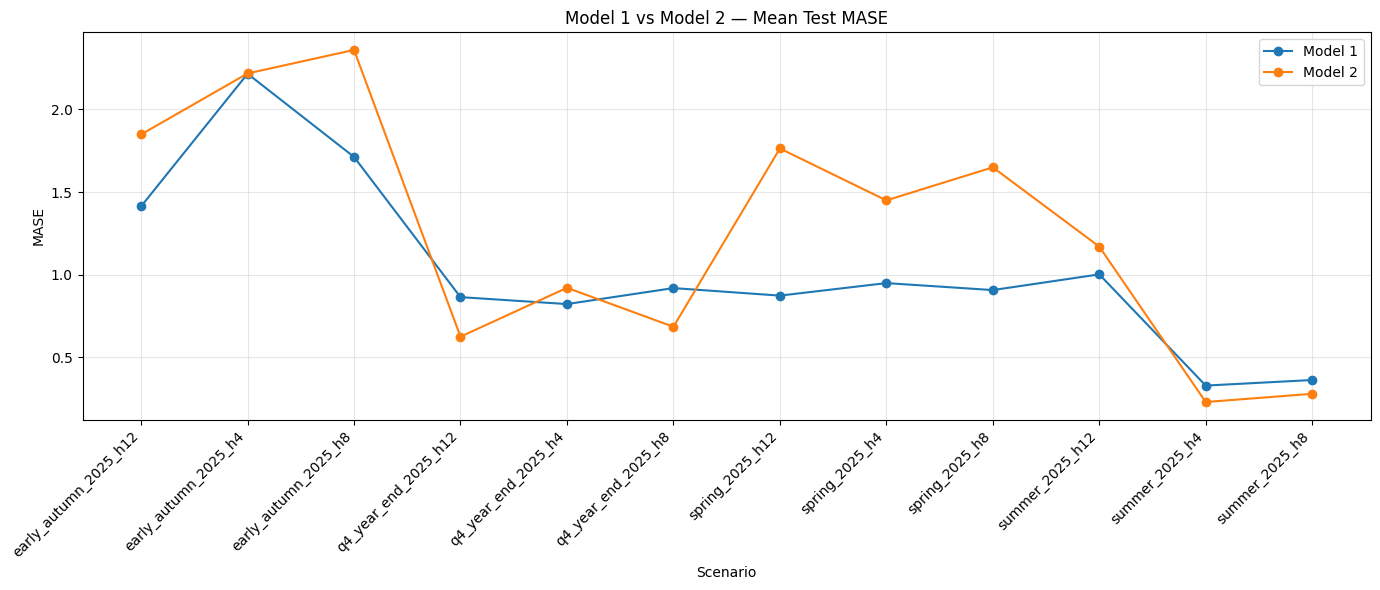

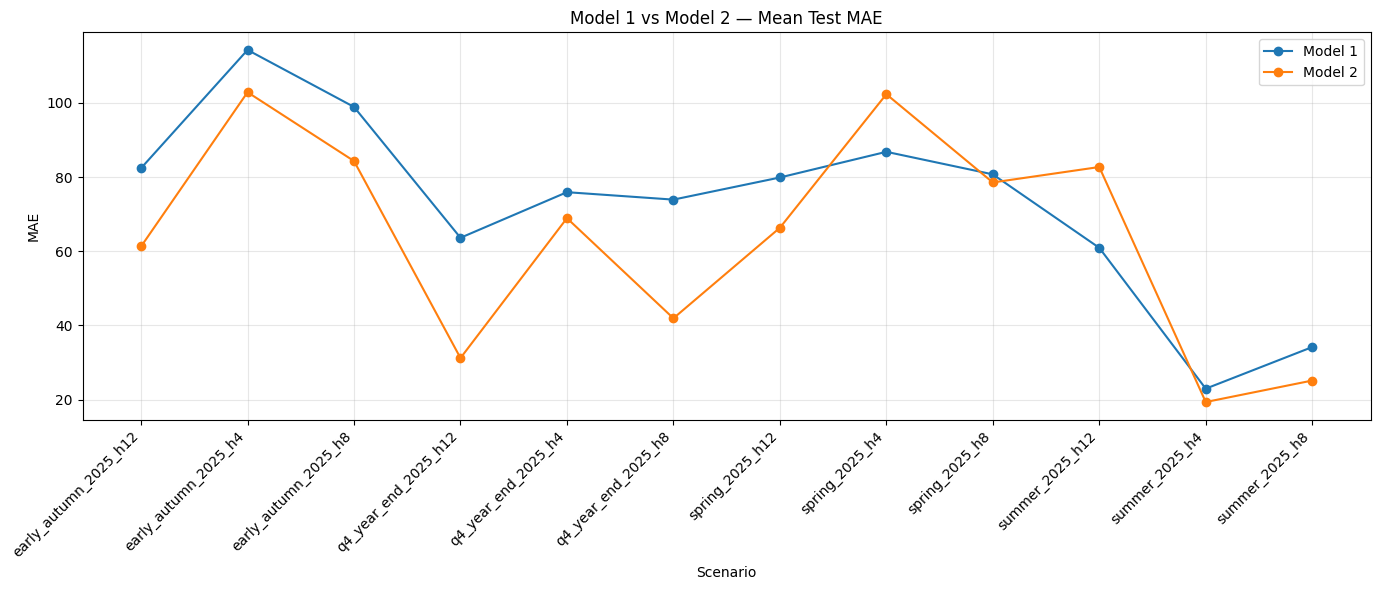

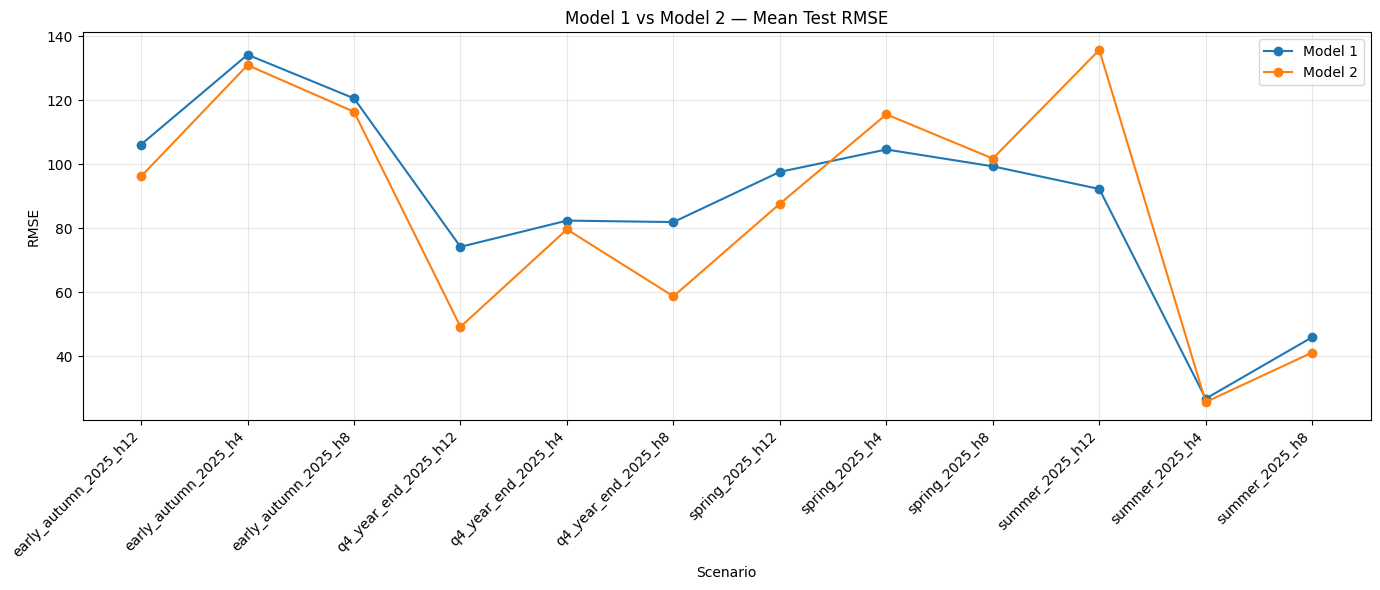

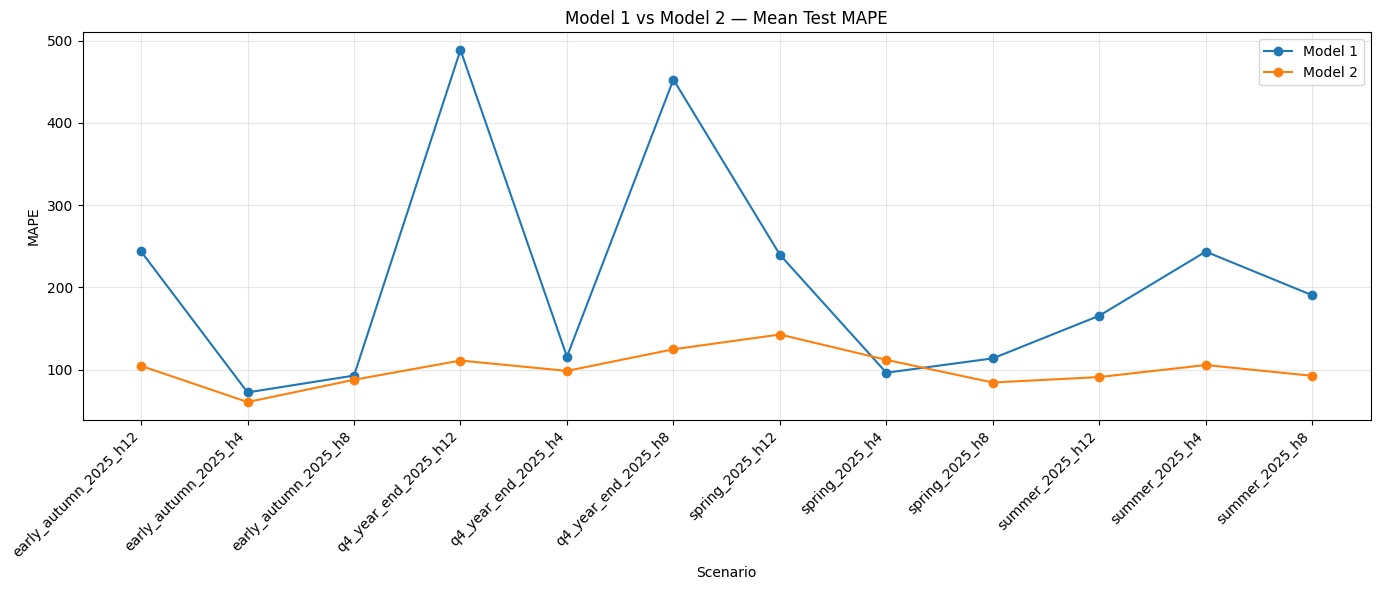

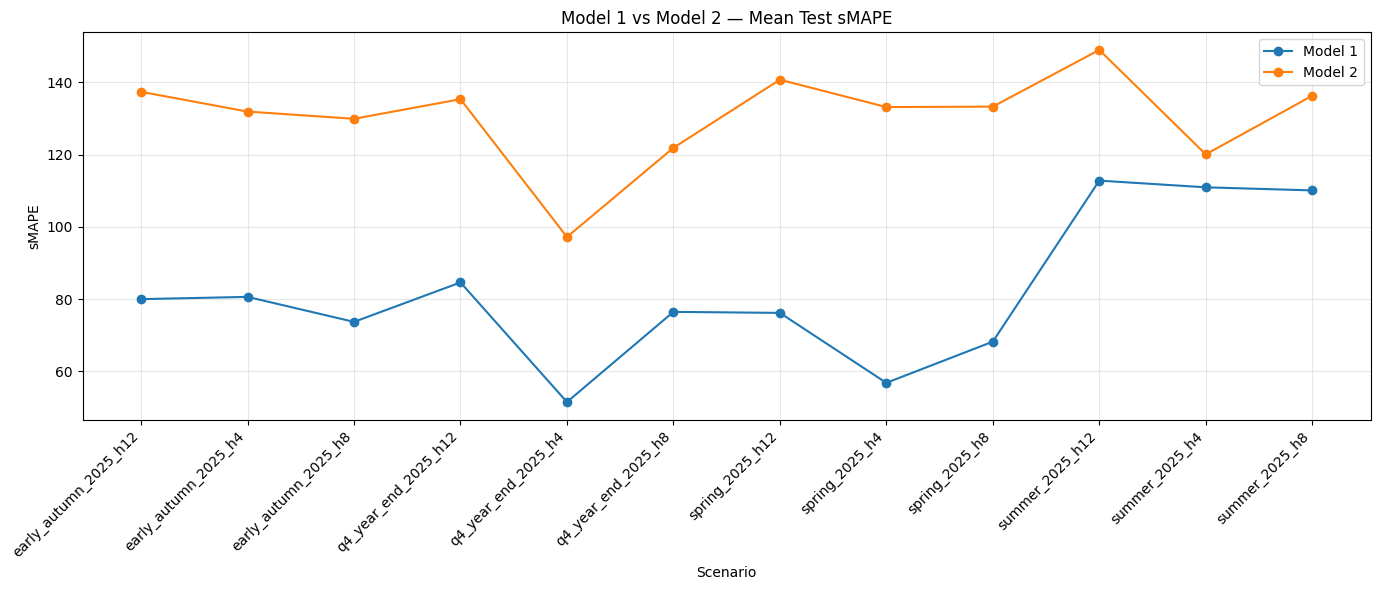

In [16]:
if MODEL_1_RESULTS.exists():
    m1=pd.read_csv(MODEL_1_RESULTS)
    m1s=(m1.groupby("scenario_id",as_index=False)
         .agg(Model_1_MAE=("MAE","mean"),Model_1_RMSE=("RMSE","mean"),
              Model_1_MAPE=("MAPE","mean"),Model_1_sMAPE=("sMAPE","mean"),
              Model_1_MASE=("MASE","mean")))
    m2s=(test_df.groupby("scenario_id",as_index=False)
         .agg(Model_2_MAE=("MAE","mean"),Model_2_RMSE=("RMSE","mean"),
              Model_2_MAPE=("MAPE","mean"),Model_2_sMAPE=("sMAPE","mean"),
              Model_2_MASE=("MASE","mean")))
    comparison=m1s.merge(m2s,on="scenario_id",how="inner")
    comparison.to_csv(OUT_DIR/"model_1_vs_model_2_comparison.csv",index=False,encoding="utf-8-sig")
    display(comparison)

    for metric in ["MASE","MAE","RMSE","MAPE","sMAPE"]:
        plt.figure(figsize=(14,6))
        plt.plot(comparison.scenario_id,comparison[f"Model_1_{metric}"],marker="o",label="Model 1")
        plt.plot(comparison.scenario_id,comparison[f"Model_2_{metric}"],marker="o",label="Model 2")
        plt.title(f"Model 1 vs Model 2 — Mean Test {metric}")
        plt.ylabel(metric); plt.xlabel("Scenario"); plt.xticks(rotation=45,ha="right")
        plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
        plt.savefig(OUT_DIR/f"plot_model1_vs_model2_{metric.lower()}.png",dpi=160); plt.show()
else:
    comparison=pd.DataFrame()
    print("Model 1 result file not found at:",MODEL_1_RESULTS)
    print("Model 2 completed normally; comparison plots were skipped.")

,outer_origin_label,horizon_weeks,mean_cv_MASE,mean_test_MASE,mean_gap,median_test_to_cv_ratio,valid_pairs
0,early_autumn_2025,4,0.358449,2.217935,1.859486,3.391995,39
1,early_autumn_2025,8,0.358449,2.360191,2.001742,2.474119,39
2,early_autumn_2025,12,0.358449,1.849016,1.490567,1.876566,39
3,q4_year_end_2025,4,0.872235,0.921228,0.048993,0.406344,39
4,q4_year_end_2025,8,0.872235,0.685443,-0.186792,0.380172,39
5,q4_year_end_2025,12,0.872235,0.625442,-0.246793,0.327650,39
6,spring_2025,4,1.337849,1.449998,0.112149,0.877830,39
7,spring_2025,8,1.337849,1.650096,0.312247,0.657197,39
8,spring_2025,12,1.337849,1.763995,0.426147,0.650728,39
9,summer_2025,4,0.685664,0.230138,-0.455526,0.244008,39


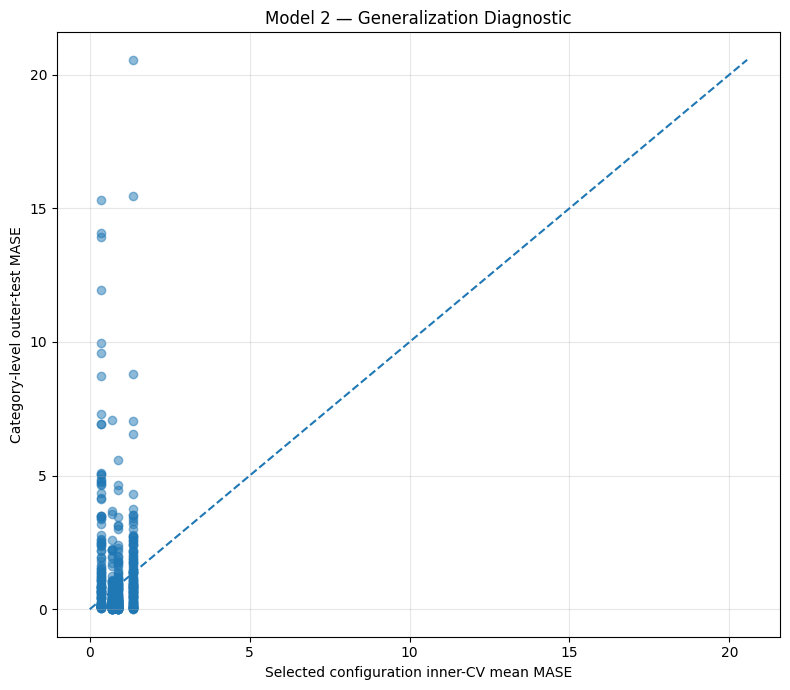

In [18]:
stability=test_df.copy()
stability["test_minus_cv_MASE"]=stability.MASE-stability.cv_mean_MASE
stability["test_to_cv_ratio"]=stability.MASE/stability.cv_mean_MASE.replace(0,np.nan)

stab=(stability.groupby(["outer_origin_label","horizon_weeks"],as_index=False)
      .agg(mean_cv_MASE=("cv_mean_MASE","mean"),
           mean_test_MASE=("MASE","mean"),
           mean_gap=("test_minus_cv_MASE","mean"),
           median_test_to_cv_ratio=("test_to_cv_ratio","median"),
           valid_pairs=("test_minus_cv_MASE","count")))
stab.to_csv(OUT_DIR/"model_2_cv_test_stability.csv",index=False,encoding="utf-8-sig")
display(stab)

q=stability[np.isfinite(stability.cv_mean_MASE)&np.isfinite(stability.MASE)]
if len(q):
    plt.figure(figsize=(8,7))
    plt.scatter(q.cv_mean_MASE,q.MASE,alpha=.5)
    mx=np.nanmax([q.cv_mean_MASE.max(),q.MASE.max()])
    plt.plot([0,mx],[0,mx],linestyle="--")
    plt.xlabel("Selected configuration inner-CV mean MASE")
    plt.ylabel("Category-level outer-test MASE")
    plt.title("Model 2 — Generalization Diagnostic")
    plt.grid(alpha=.3); plt.tight_layout()
    plt.savefig(OUT_DIR/"plot_cv_vs_test_mase.png",dpi=160); plt.show()

,Product Category,mean_MAE,mean_RMSE,mean_MAPE,mean_sMAPE,mean_MASE,std_MASE
17,ΛΑΙΜΟΣ,0.913893,1.102767,NaN,132.638889,7.619811,7.198876
3,ΓΑΝΤΙ ΑΝΔΡΙΚΟ,11.495075,15.405336,90.482870,141.143582,4.636311,4.741895
18,ΜΠΛΟΥΖΑ,0.948422,1.132947,100.000000,125.000000,2.886974,2.956986
5,ΓΟΥΝΑ,21.840697,28.453897,84.948810,127.981496,2.842917,3.381771
12,ΚΑΠΑ,50.308527,70.787941,78.934030,123.048789,1.942349,2.294192
19,ΜΠΡΕΛΟΚ,1.340475,1.877736,87.890984,153.680345,1.919352,1.657553
30,ΣΚΟΥΦΟΣ ΑΝΔΡΙΚΟΣ,26.500705,35.111540,108.169151,132.857356,1.890480,1.845741
11,ΚAΣΚΟΛ,318.845371,510.403765,166.607869,123.878058,1.817223,1.712898
4,ΓΑΝΤΙ ΓΥΝΑΙΚΕΙΟ,92.467935,120.876972,90.491241,139.206211,1.658114,1.866401
32,ΤΑΞΙΔΙΟΥ,1.112159,1.291643,NaN,169.444444,1.604170,1.081257


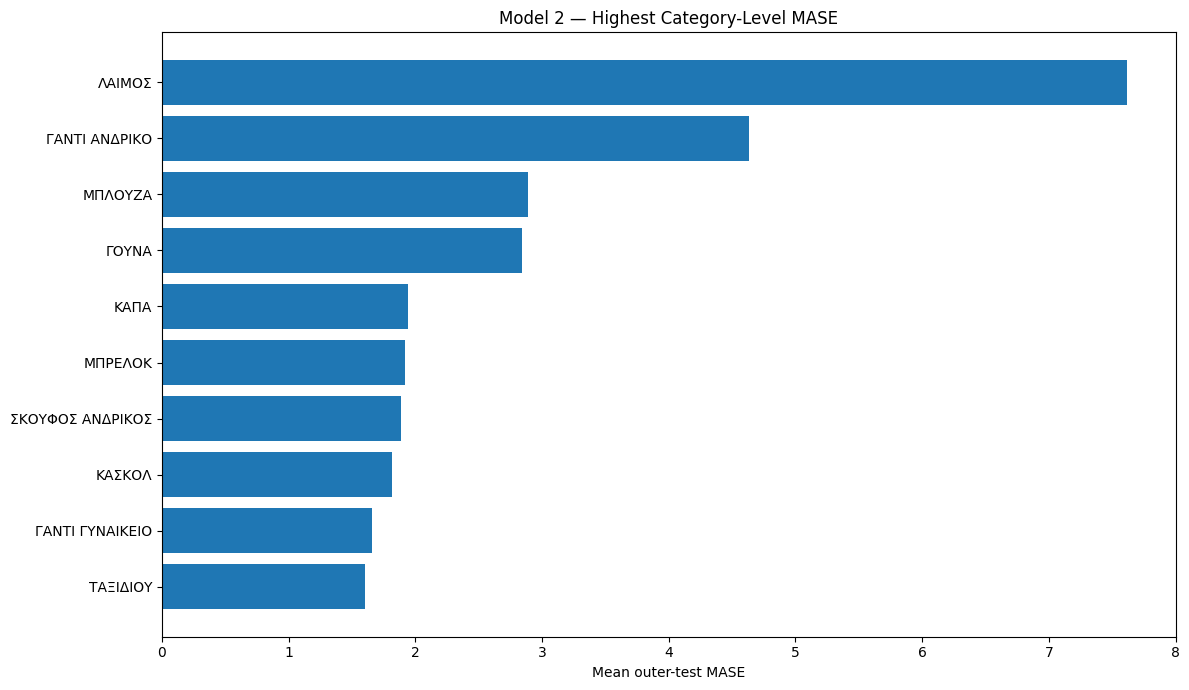

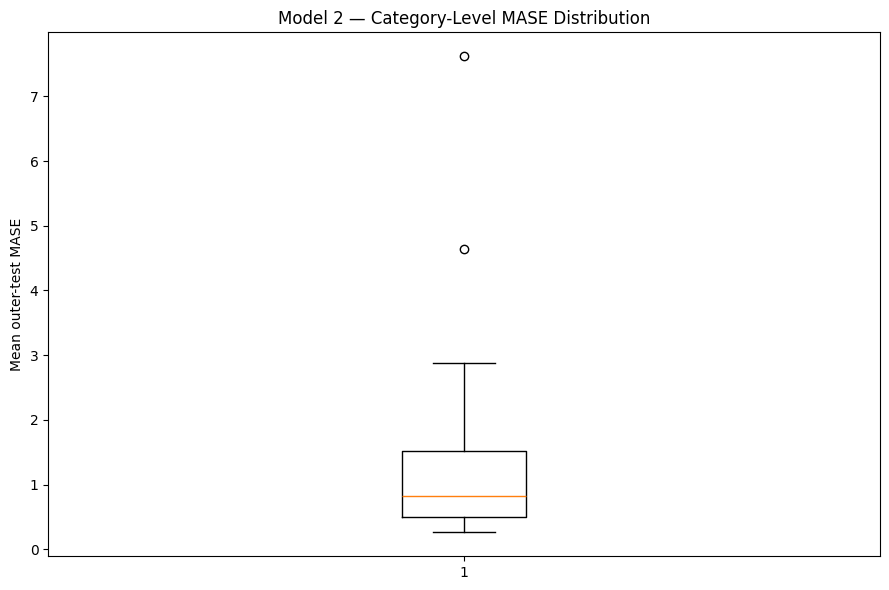

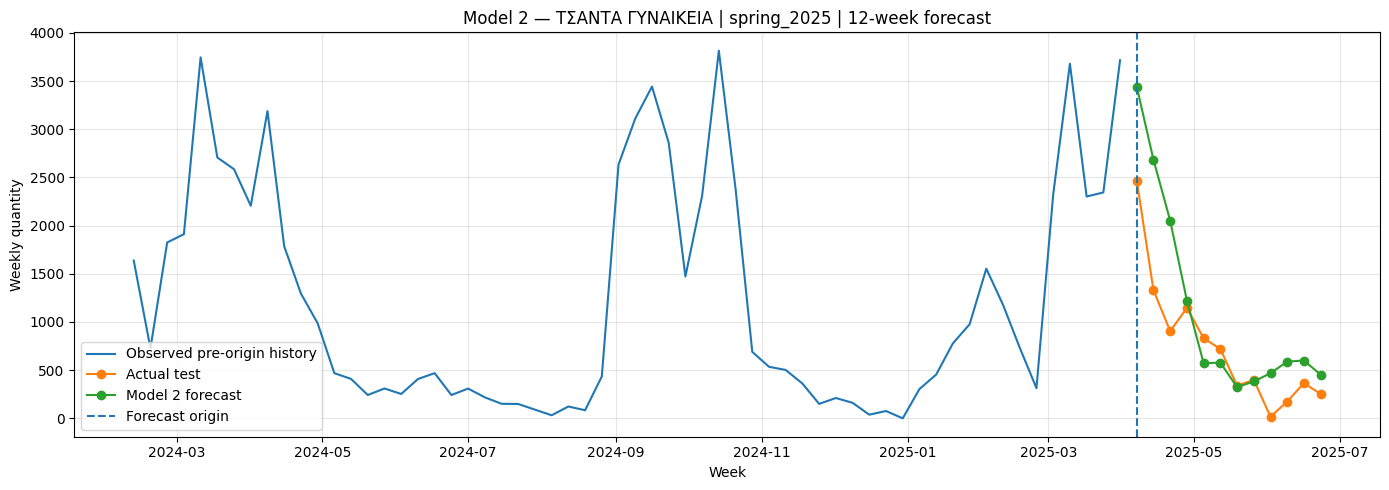

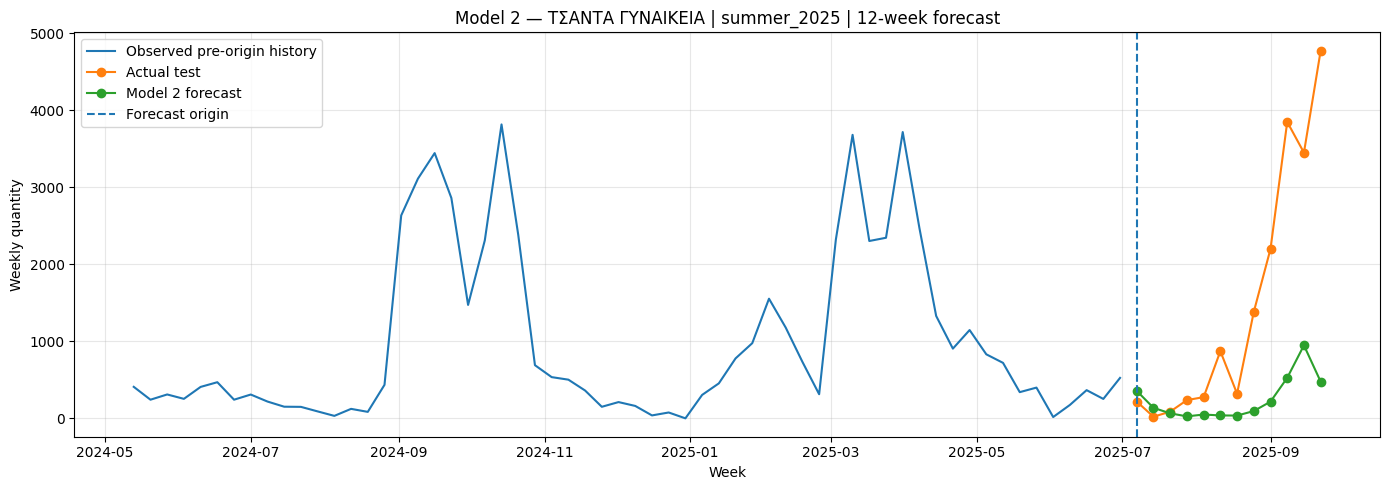

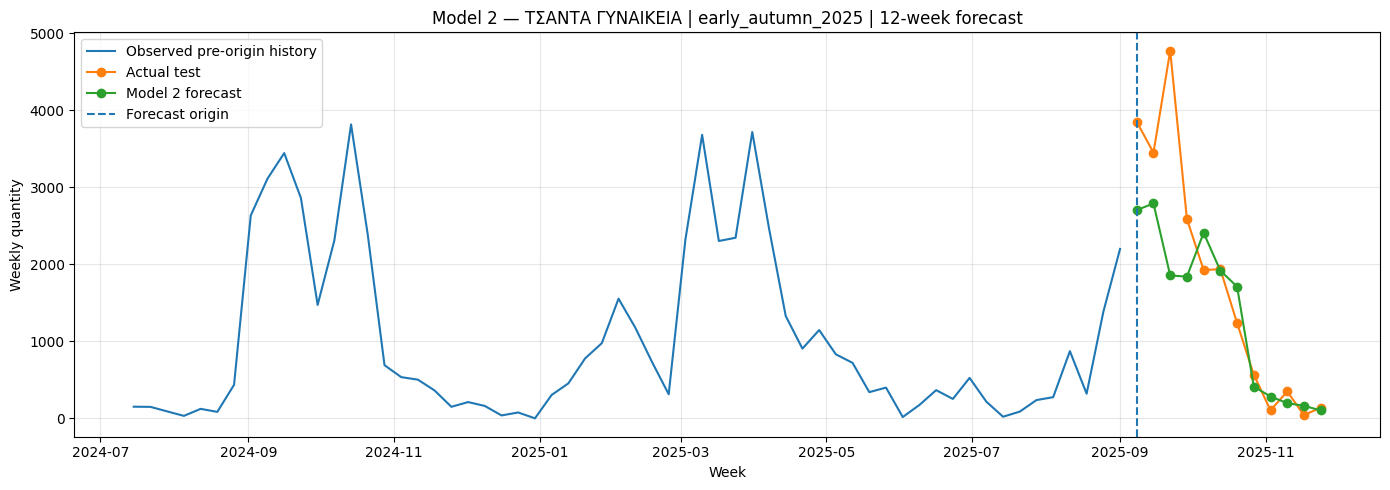

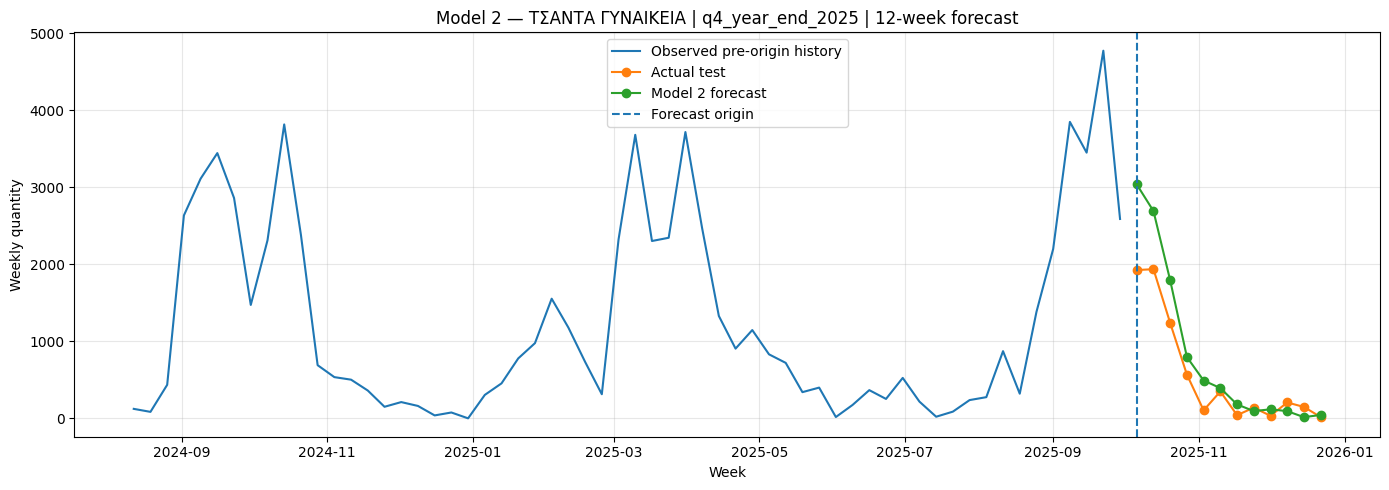

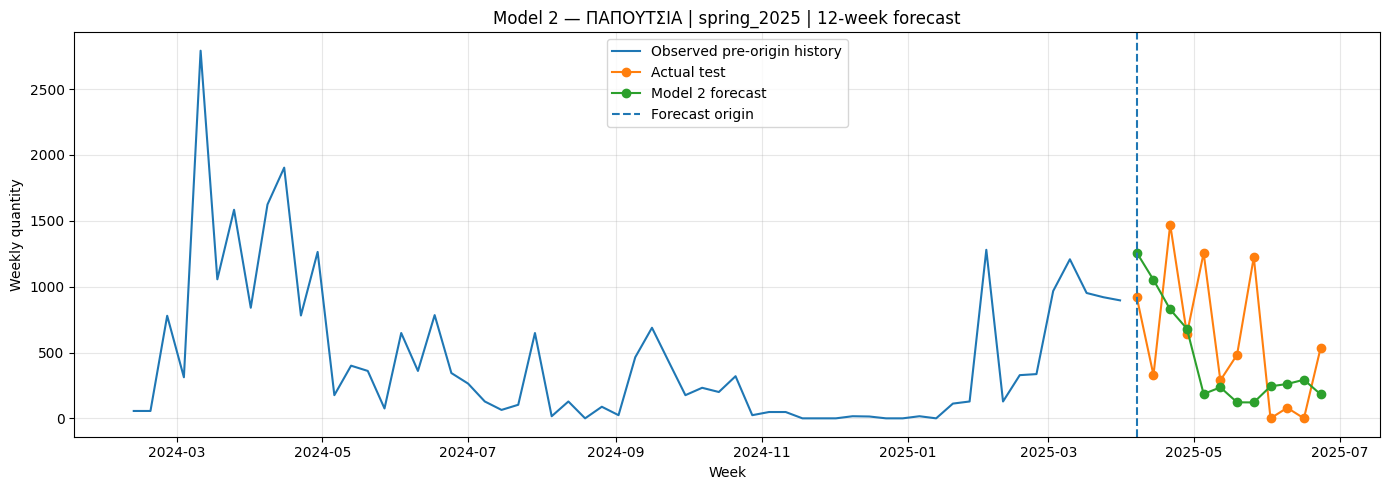

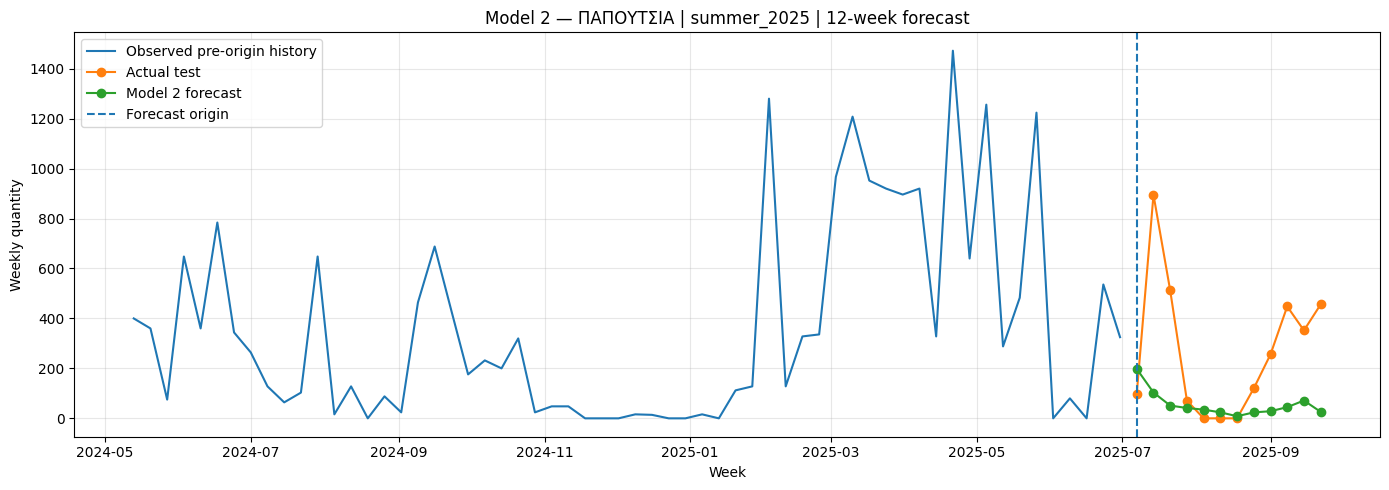

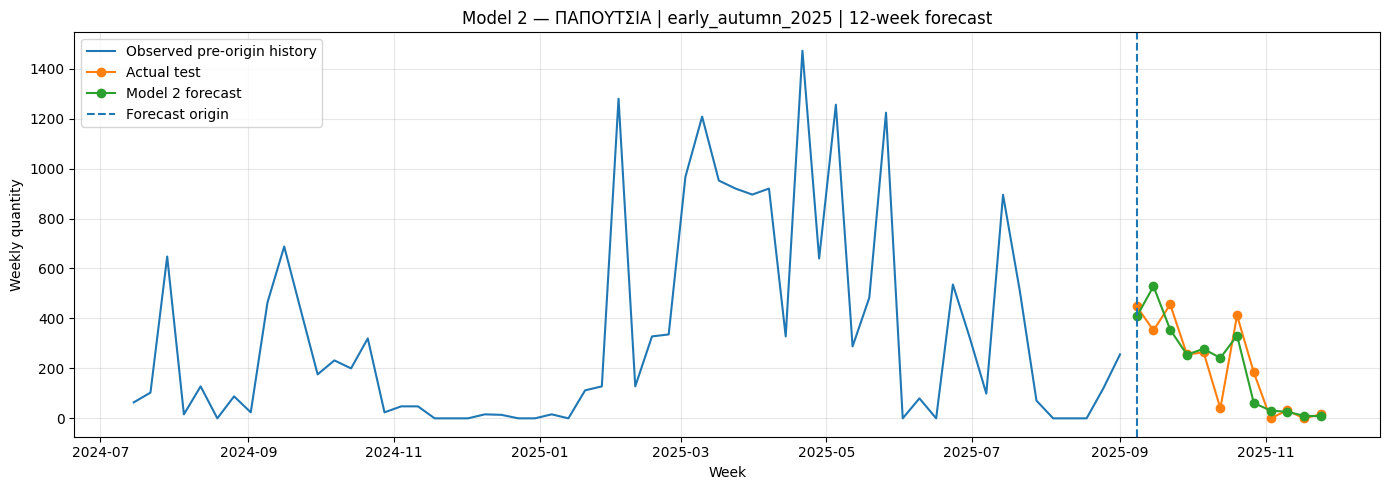

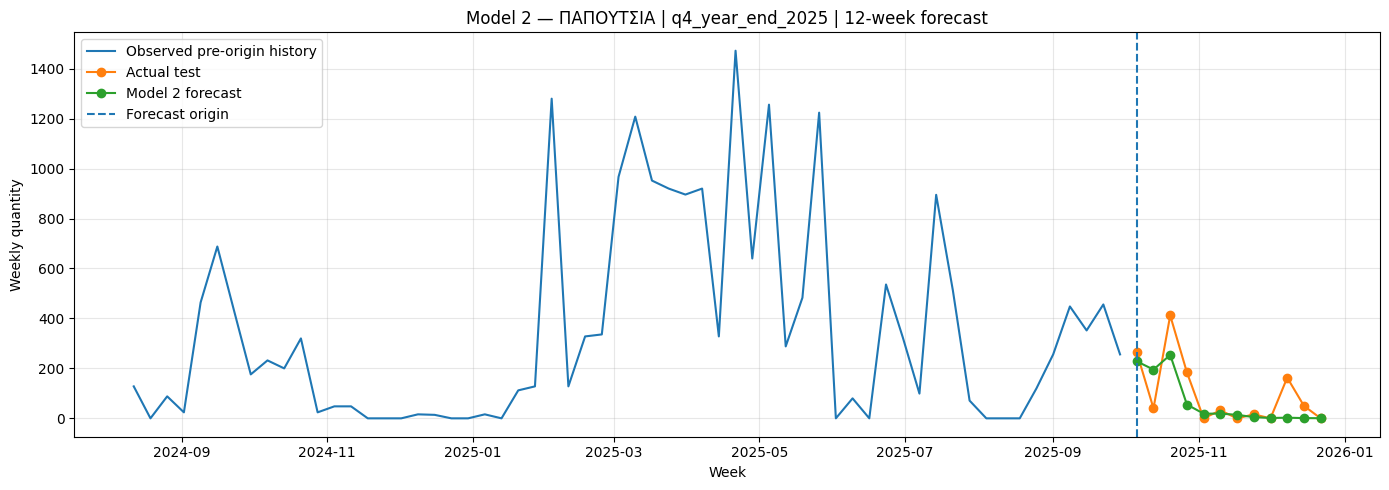

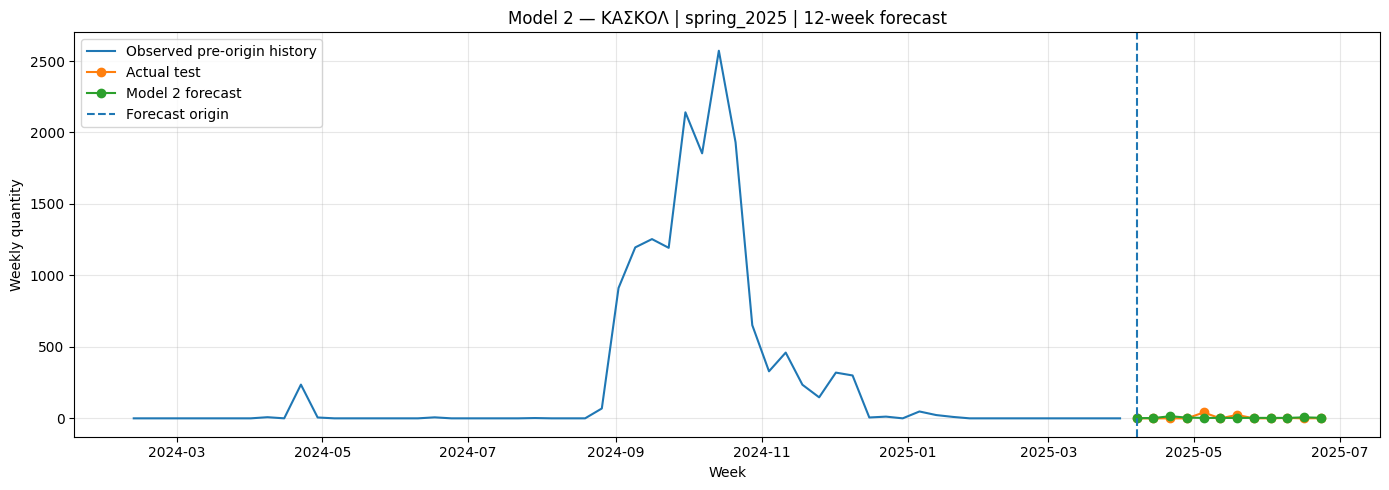

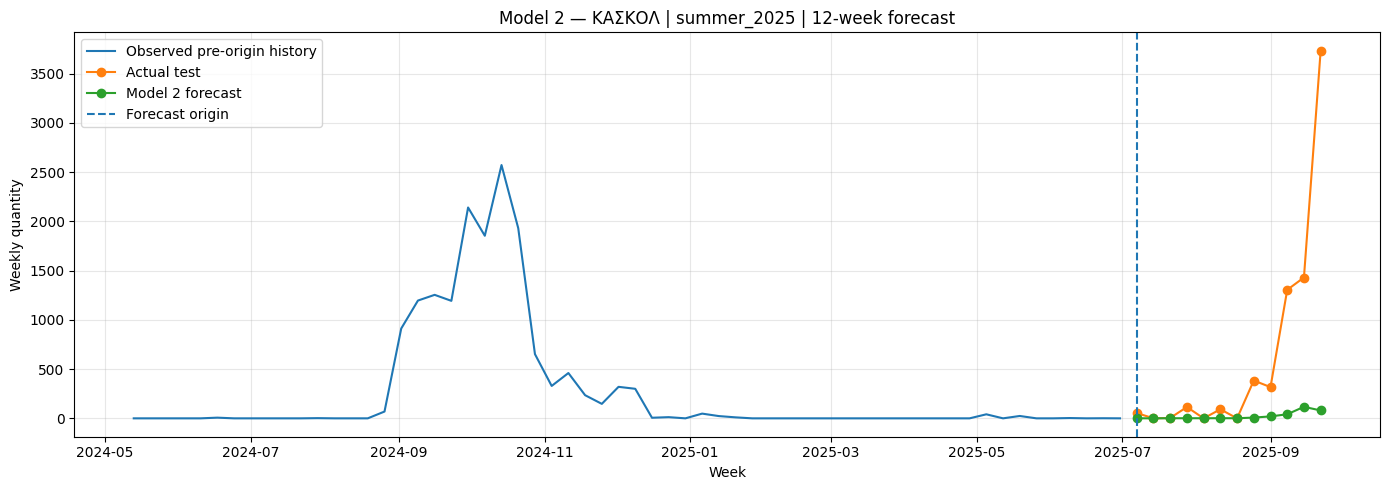

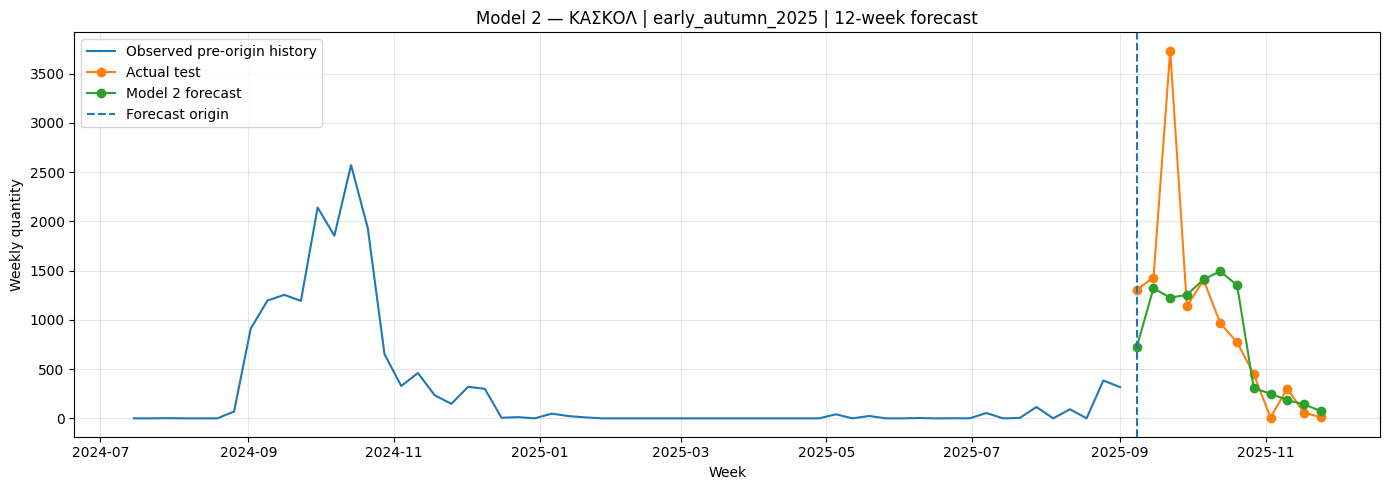

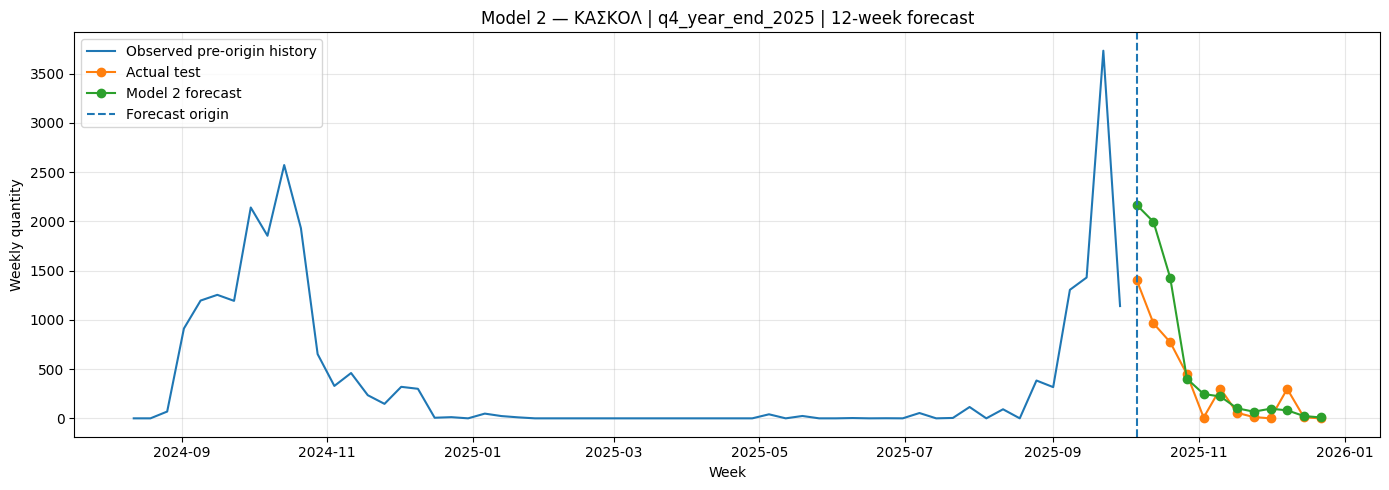

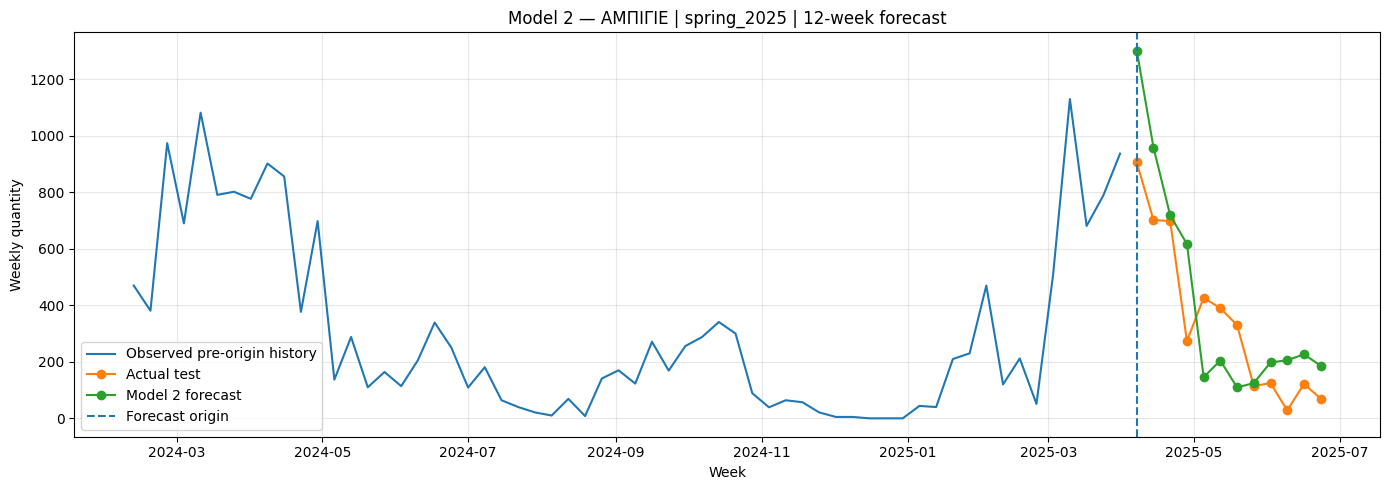

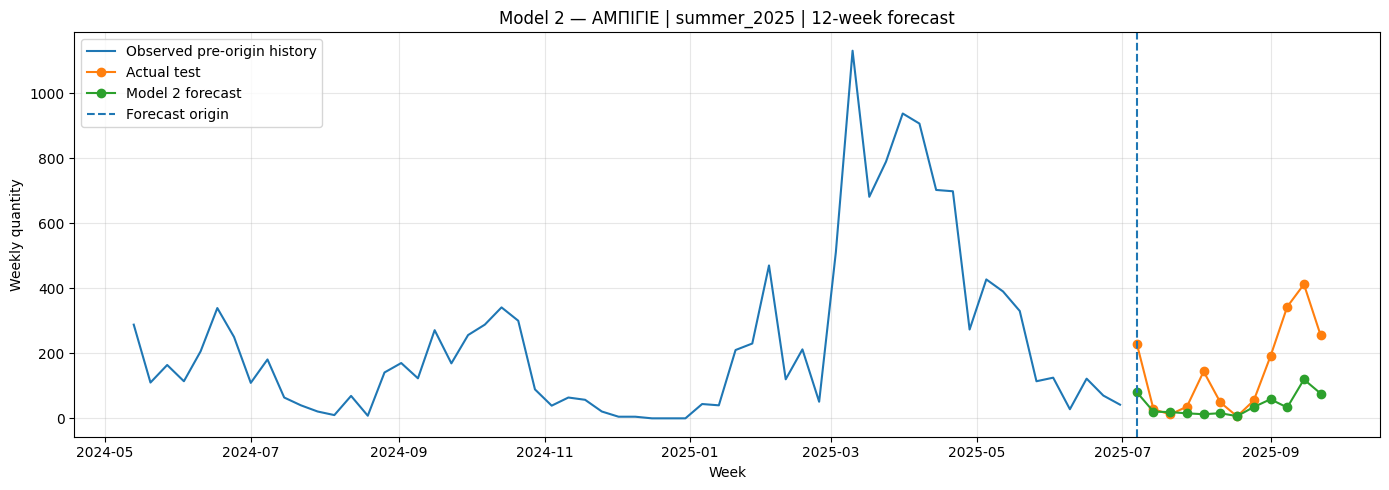

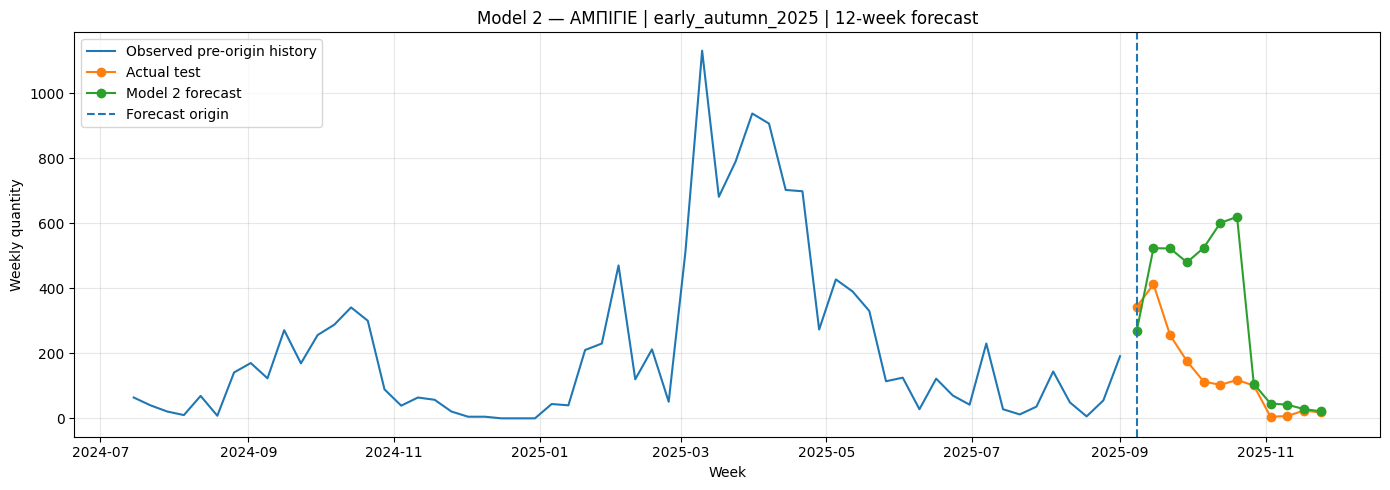

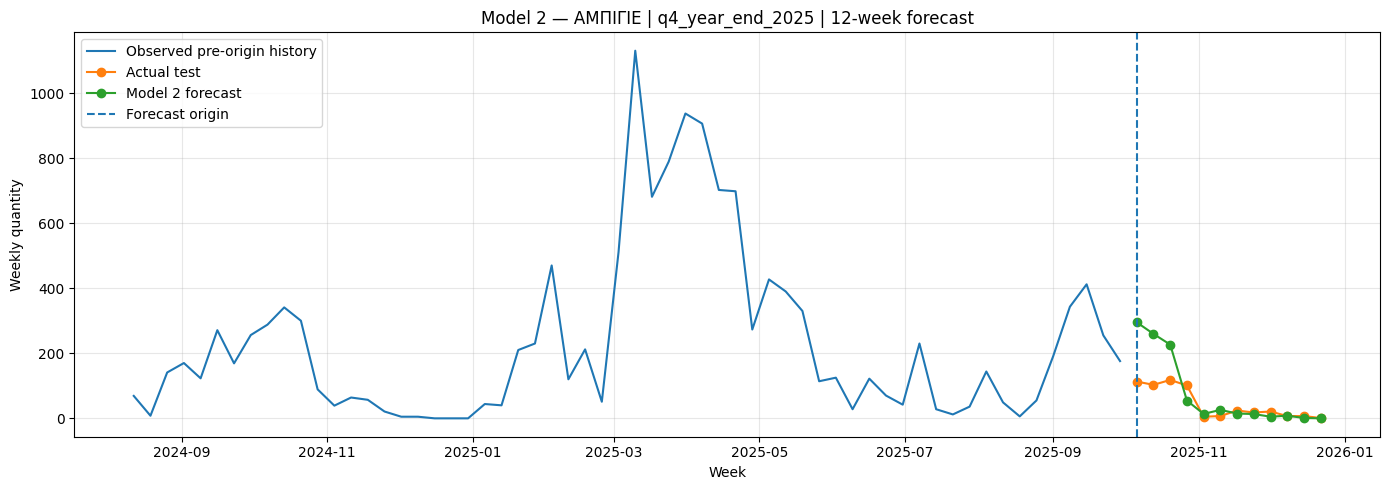

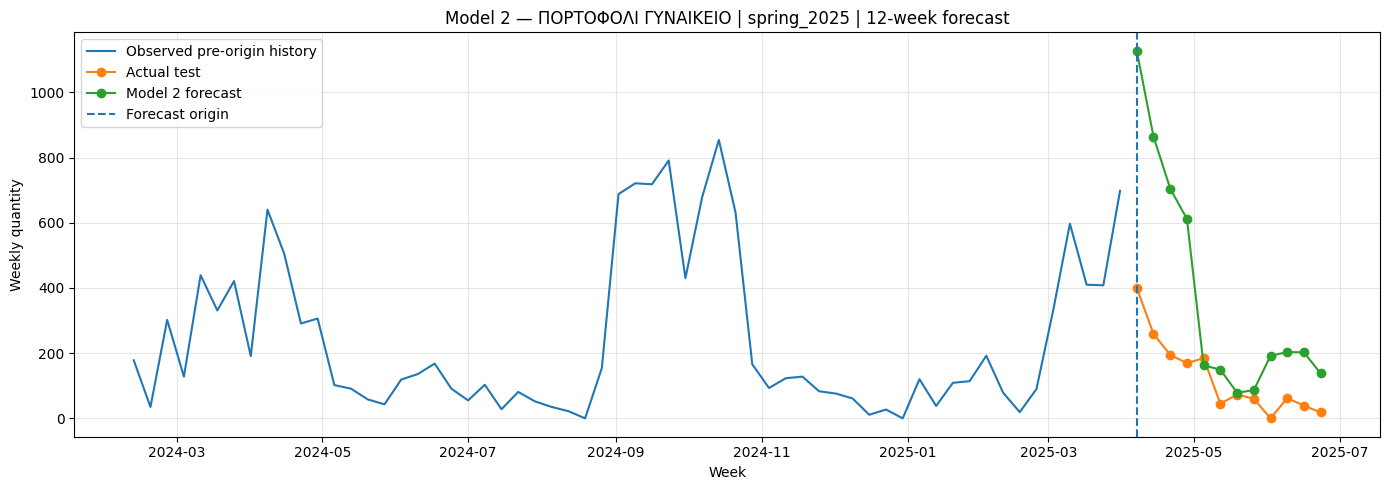

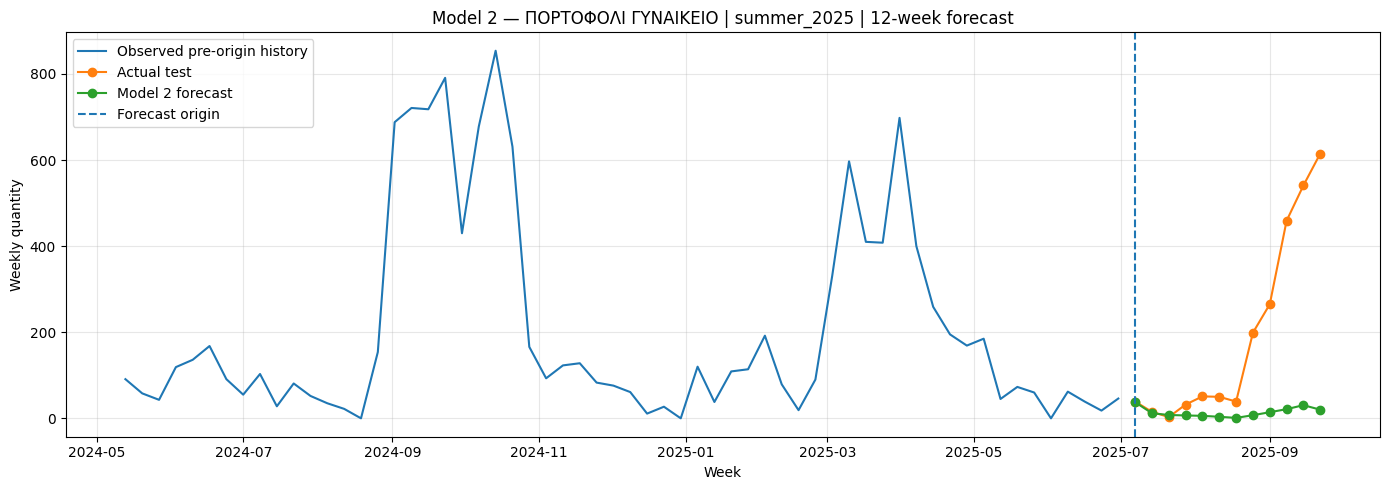

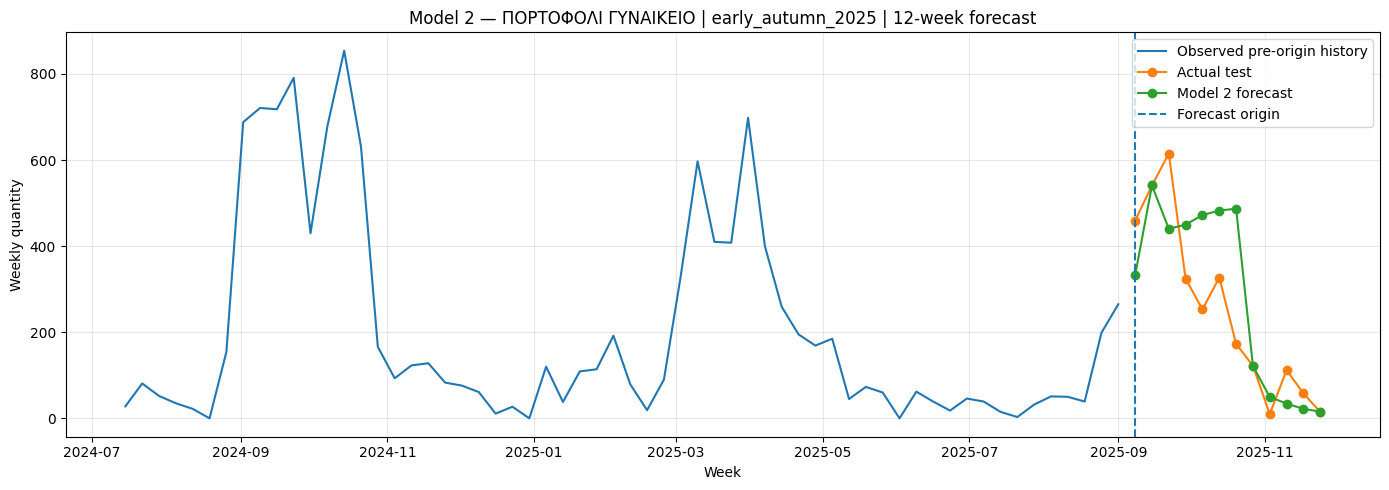

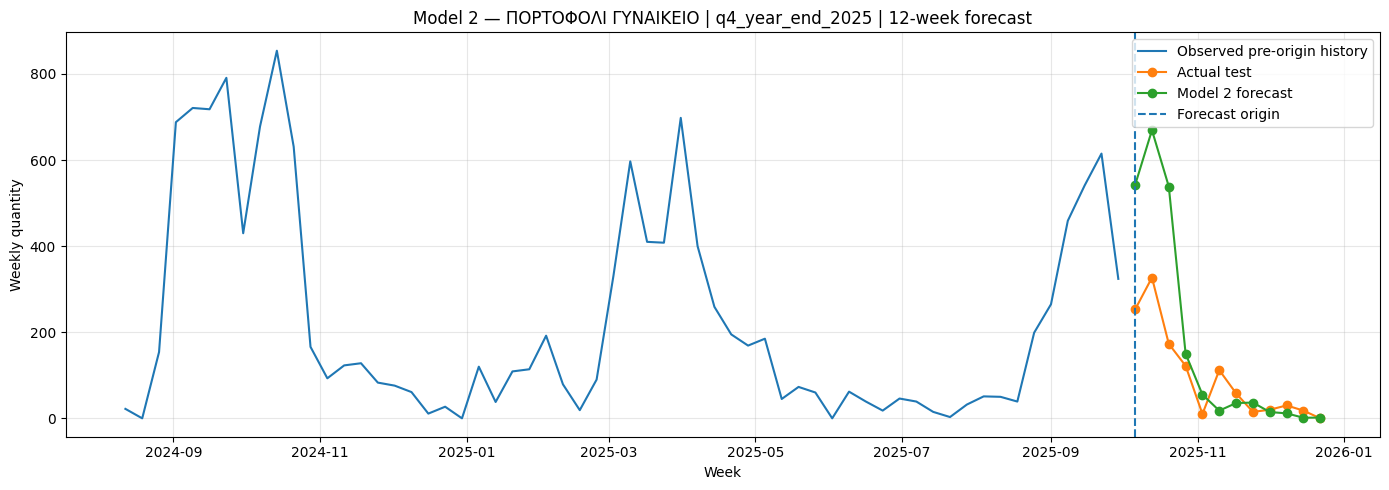

In [19]:
cat_summary=(test_df.groupby(CATEGORY_COL,as_index=False)
             .agg(mean_MAE=("MAE","mean"),mean_RMSE=("RMSE","mean"),
                  mean_MAPE=("MAPE","mean"),mean_sMAPE=("sMAPE","mean"),
                  mean_MASE=("MASE","mean"),std_MASE=("MASE","std"))
             .sort_values("mean_MASE",ascending=False))
cat_summary.to_csv(OUT_DIR/"model_2_category_error_summary.csv",index=False,encoding="utf-8-sig")
display(cat_summary.head(10))

plt.figure(figsize=(12,7))
w=cat_summary.head(10)
plt.barh(w[CATEGORY_COL].astype(str),w.mean_MASE)
plt.xlabel("Mean outer-test MASE")
plt.title("Model 2 — Highest Category-Level MASE")
plt.gca().invert_yaxis(); plt.tight_layout()
plt.savefig(OUT_DIR/"plot_worst_categories_mase.png",dpi=160); plt.show()

plt.figure(figsize=(9,6))
plt.boxplot(cat_summary.mean_MASE.dropna())
plt.ylabel("Mean outer-test MASE")
plt.title("Model 2 — Category-Level MASE Distribution")
plt.tight_layout()
plt.savefig(OUT_DIR/"plot_category_mase_distribution.png",dpi=160); plt.show()

top5=(panel.groupby(CATEGORY_COL,as_index=False)[TARGET_COL].sum()
      .sort_values(TARGET_COL,ascending=False).head(5)[CATEGORY_COL].tolist())

for cat in top5:
    hist=panel[panel[CATEGORY_COL]==cat]
    for label in origin_order:
        f=forecasts_df[(forecasts_df[CATEGORY_COL]==cat)&
                       (forecasts_df.outer_origin_label==label)&
                       (forecasts_df.horizon_weeks==12)].copy()
        if f.empty: continue
        origin=pd.Timestamp(f.outer_origin.iloc[0])
        hp=hist[(hist[DATE_COL]>=origin-pd.Timedelta(weeks=60))&(hist[DATE_COL]<origin)]
        plt.figure(figsize=(14,5))
        plt.plot(hp[DATE_COL],hp[TARGET_COL],label="Observed pre-origin history")
        plt.plot(f[DATE_COL],f.y_true,marker="o",label="Actual test")
        plt.plot(f[DATE_COL],f.y_pred,marker="o",label="Model 2 forecast")
        plt.axvline(origin,linestyle="--",label="Forecast origin")
        plt.title(f"Model 2 — {cat} | {label} | 12-week forecast")
        plt.xlabel("Week"); plt.ylabel("Weekly quantity"); plt.legend(); plt.grid(alpha=.3)
        plt.tight_layout()
        safe=str(cat).replace("/","_").replace(" ","_")
        plt.savefig(OUT_DIR/f"plot_forecast_{safe}_{label}_h12.png",dpi=160); plt.show()

,feature,mean_abs_shap
9,lag_1,0.447453
16,rolling_mean_4,0.403401
15,lag_52,0.206950
10,lag_2,0.180553
5,week_sin,0.151785
20,rolling_mean_8,0.110789
36,recent_positive_ratio_4,0.090843
0,category_encoded,0.084366
6,week_cos,0.083738
21,rolling_std_8,0.079862


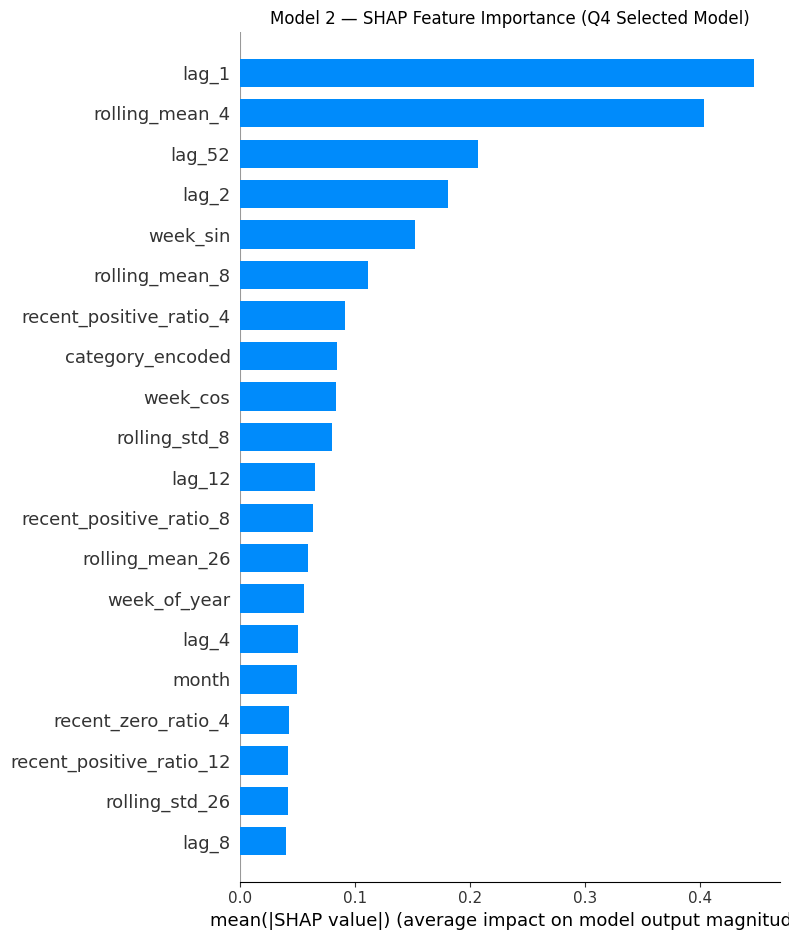

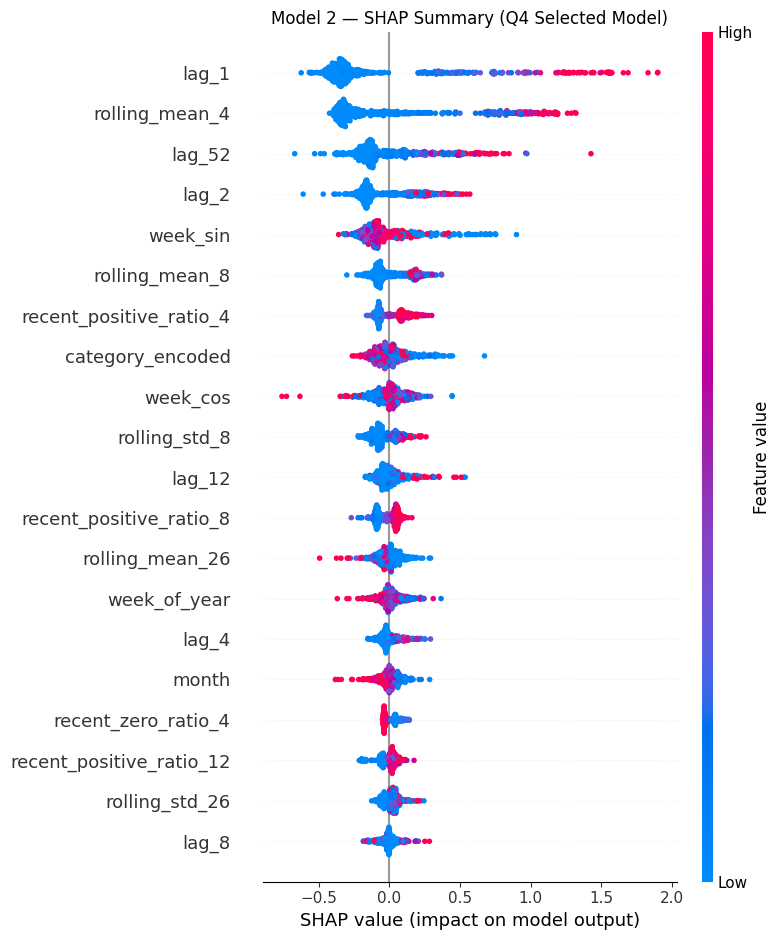

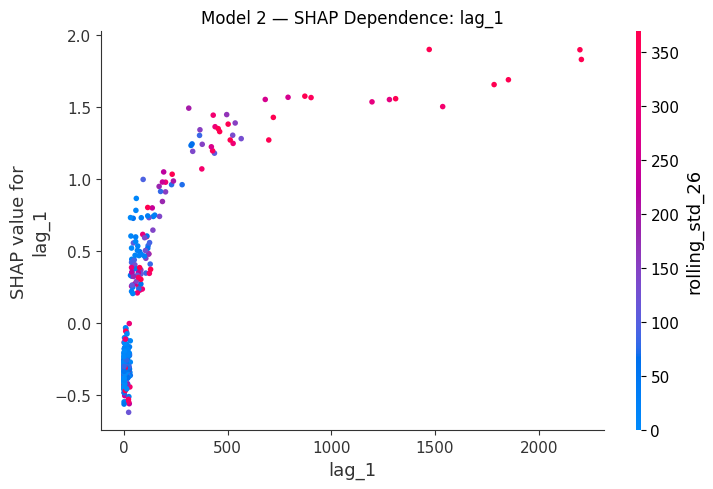

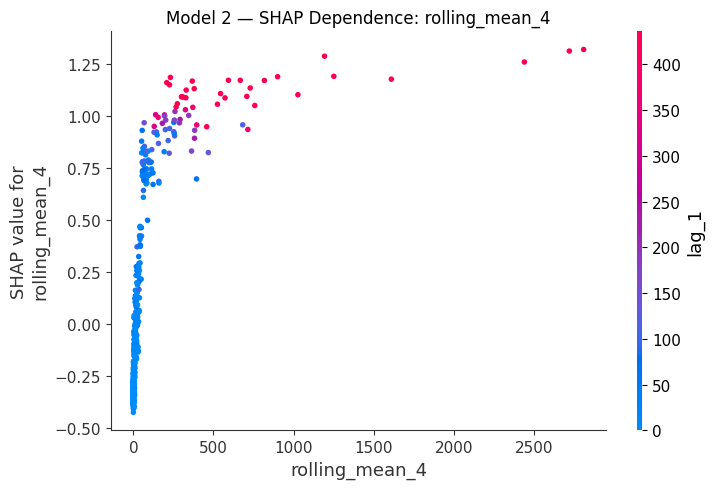

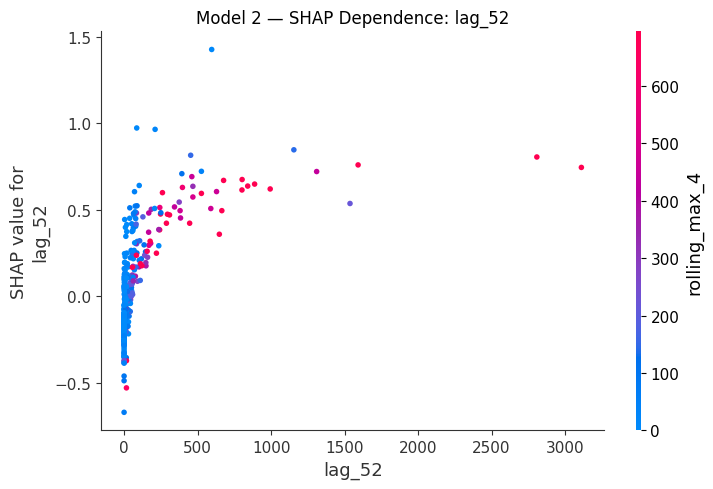

In [20]:
SHAP_ORIGIN="q4_year_end_2025"

if SHAP_AVAILABLE and SHAP_ORIGIN in trained_models:
    bundle=trained_models[SHAP_ORIGIN]
    model=bundle["model"]
    supervised=bundle["supervised"]
    n=min(500,len(supervised))
    X_shap=supervised.sample(n=n,random_state=RANDOM_STATE)[FEATURE_COLUMNS].astype(float)

    try:
        explainer=shap.TreeExplainer(model)
        sv=explainer.shap_values(X_shap)
        if isinstance(sv,list): sv=sv[0]

        imp=pd.DataFrame({
            "feature":FEATURE_COLUMNS,
            "mean_abs_shap":np.abs(sv).mean(axis=0)
        }).sort_values("mean_abs_shap",ascending=False)
        imp.to_csv(OUT_DIR/"model_2_shap_feature_importance.csv",index=False,encoding="utf-8-sig")
        display(imp.head(20))

        shap.summary_plot(sv,X_shap,plot_type="bar",show=False)
        plt.title("Model 2 — SHAP Feature Importance (Q4 Selected Model)")
        plt.tight_layout()
        plt.savefig(OUT_DIR/"plot_shap_bar.png",dpi=160,bbox_inches="tight"); plt.show()

        shap.summary_plot(sv,X_shap,show=False)
        plt.title("Model 2 — SHAP Summary (Q4 Selected Model)")
        plt.tight_layout()
        plt.savefig(OUT_DIR/"plot_shap_summary.png",dpi=160,bbox_inches="tight"); plt.show()

        for feature in imp.head(3).feature:
            shap.dependence_plot(feature,sv,X_shap,show=False)
            plt.title(f"Model 2 — SHAP Dependence: {feature}")
            plt.tight_layout()
            safe=feature.replace("/","_").replace(" ","_")
            plt.savefig(OUT_DIR/f"plot_shap_dependence_{safe}.png",dpi=160,bbox_inches="tight")
            plt.show()
    except Exception as e:
        print("SHAP analysis failed:",e)
else:
    print("SHAP skipped.")

In [22]:
log={
    "run_timestamp":datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "model":"Model 2 - Global Tree-Based Forecasting",
    "input_file":str(INPUT_FILE),
    "outer_origins":OUTER_ORIGINS,
    "forecast_horizons":FORECAST_HORIZONS,
    "inner_cv_horizon":INNER_CV_HORIZON,
    "inner_cv_offsets_weeks":INNER_CV_OFFSETS_WEEKS,
    "forecast_strategy":"recursive multi-step global forecasting",
    "candidate_count":len(CANDIDATES),
    "candidate_configurations":CANDIDATES,
    "target_transformations":TARGET_TRANSFORMATIONS,
    "feature_columns":FEATURE_COLUMNS,
    "MASE_m":52,
    "MASE_denominator":"per-category pre-origin mean absolute 52-week seasonal-naive error",
    "undefined_MASE_policy":"NaN when m=52 scale is zero/non-finite; no m=1 fallback and no epsilon substitution.",
    "selection_rule":"lowest mean category-level inner-CV MASE; tie-break by MASE std, RMSE, MAE; sMAPE fallback only if MASE is unavailable.",
    "future_feature_policy":"calendar/static category features are known; every demand-derived feature is generated from pre-week history; recursive horizons use previous predictions, not future actual demand.",
    "same_week_business_features_excluded":[
        "weekly_revenue","transaction_count","active_customer_count",
        "unique_customers","unique_skus","demand_positive"
    ],
    "shap_model":"Q4 selected model, selected before Q4 outer test"
}
with open(OUT_DIR/"model_2_experiment_log.json","w",encoding="utf-8") as f:
    json.dump(log,f,indent=2,ensure_ascii=False,default=str)

required=[
    "model_2_candidate_configurations.csv",
    "model_2_inner_cv_all_trials.csv",
    "model_2_selected_configurations.csv",
    "model_2_outer_test_results.csv",
    "model_2_outer_forecasts.csv",
    "model_2_scenario_summary.csv",
    "model_2_overall_summary.csv",
    "model_2_integrity_audit.csv",
    "model_2_feature_columns.csv",
    "model_2_experiment_log.json"
]
for name in required:
    p=OUT_DIR/name
    if not p.exists(): raise FileNotFoundError(p)
    print("OK:",name)

print("\nMODEL 2")
print("Outputs:",OUT_DIR)

OK: model_2_candidate_configurations.csv
OK: model_2_inner_cv_all_trials.csv
OK: model_2_selected_configurations.csv
OK: model_2_outer_test_results.csv
OK: model_2_outer_forecasts.csv
OK: model_2_scenario_summary.csv
OK: model_2_overall_summary.csv
OK: model_2_integrity_audit.csv
OK: model_2_feature_columns.csv
OK: model_2_experiment_log.json

MODEL 2
Outputs: /content/drive/MyDrive/model_2_tree_based_rolling_origin_outputs
